In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session


/kaggle/input/melting-point/sample_submission.csv
/kaggle/input/melting-point/train.csv
/kaggle/input/melting-point/test.csv


In [3]:
df = pd.read_csv("/kaggle/input/melting-point/sample_submission.csv")
df.head()

,id,Tm
0,1022,0
1,1146,0
2,79,0
3,2279,0
4,1342,0


In [4]:
df_train = pd.read_csv("/kaggle/input/melting-point/train.csv")
df_train.head()

,id,SMILES,Tm,Group 1,Group 2,Group 3,Group 4,Group 5,Group 6,Group 7,...,Group 415,Group 416,Group 417,Group 418,Group 419,Group 420,Group 421,Group 422,Group 423,Group 424
0,2175,FC1=C(F)C(F)(F)C1(F)F,213.15,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1222,c1ccc2c(c1)ccc3Nc4ccccc4c23,407.15,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2994,CCN1C(C)=Nc2ccccc12,324.15,2,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1704,CC#CC(=O)O,351.15,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2526,CCCCC(S)C,126.15,2,3,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## EDA

In [5]:
# EDA completo para "Thermophysical Property: Melting Point"
# Requisitos: pandas, numpy, matplotlib, seaborn, scikit-learn, missingno (opcional)
# pip install pandas numpy matplotlib seaborn scikit-learn missingno

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set(style="whitegrid", context="notebook", rc={"figure.dpi": 150})
OUTDIR = "eda_outputs"
os.makedirs(OUTDIR, exist_ok=True)

# 1) Cargar datos
df = pd.read_csv("/kaggle/input/melting-point/train.csv")
print("Shape:", df.shape)
display(df.head())

# 2) Información general y valores faltantes
print("\nColumn types and non-null counts:")
display(df.info())
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_table = pd.concat([missing, missing_pct], axis=1)
missing_table.columns = ["missing_count", "missing_pct"]
display(missing_table[missing_table["missing_count"]>0])

# 3) Identificar columnas de descriptor (Group features)
exclude = {"id", "SMILES", "Tm"}
group_cols = [c for c in df.columns if c not in exclude]
print(f"\nDetected {len(group_cols)} feature columns (assumed group descriptors).")
print("First 20 feature columns:", group_cols[:20])

# 4) Duplicados / ids únicos / SMILES duplicados
print("\nIDs unique?", df['id'].nunique() == len(df))
dups_by_smiles = df[df.duplicated("SMILES", keep=False)].sort_values("SMILES")
print("Number of SMILES duplicated (any):", dups_by_smiles['SMILES'].nunique())
if not dups_by_smiles.empty:
    display(dups_by_smiles.head(20))

# 5) Target (Tm) distribution and stats
print("\nTm (K) summary:")
display(df["Tm"].describe())
print("Skewness:", df["Tm"].skew(), "Kurtosis:", df["Tm"].kurtosis())

plt.figure(figsize=(6,4))
sns.histplot(df["Tm"], bins=50, kde=True)
plt.title("Distribución de Tm (K)")
plt.xlabel("Tm (K)")
plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, "tm_hist.png"))
plt.close()

plt.figure(figsize=(6,3))
sns.boxplot(x=df["Tm"])
plt.title("Boxplot de Tm")
plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, "tm_box.png"))
plt.close()

# 6) Outliers en Tm (IQR)
q1, q3 = df["Tm"].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
outliers = df[(df["Tm"] < lower) | (df["Tm"] > upper)]
print("Outliers detectados (IQR):", len(outliers))
if len(outliers) > 0:
    display(outliers[["id","SMILES","Tm"]].head())

# 7) Estadísticas básicas para features de grupos (sparsity, var, mean)
feat_stats = df[group_cols].describe().T
feat_stats["zero_frac"] = (df[group_cols] == 0).sum() / len(df)
feat_stats["variance"] = df[group_cols].var()
feat_stats = feat_stats.sort_values("zero_frac", ascending=True)
display(feat_stats.head(10))
feat_stats.to_csv(os.path.join(OUTDIR, "feature_stats.csv"))

# 8) Columnas con casi toda la información a cero (low-variance / sparse)
sparse_threshold = 0.98
very_sparse = feat_stats[feat_stats["zero_frac"] >= sparse_threshold].index.tolist()
print(f"Columnas con >= {int(sparse_threshold*100)}% ceros: {len(very_sparse)}")
pd.Series(very_sparse).to_csv(os.path.join(OUTDIR, "very_sparse_features.txt"), index=False)

# 9) Correlación simple con el target (pearson)
corr_with_target = df[group_cols].corrwith(df["Tm"]).sort_values(key=lambda x: x.abs(), ascending=False)
top_corr = corr_with_target.head(30)
display(top_corr)
top_corr.to_csv(os.path.join(OUTDIR, "top_corr_with_Tm.csv"))

plt.figure(figsize=(8,6))
sns.barplot(x=top_corr.values, y=top_corr.index)
plt.title("Top 30 features correlacionadas (Pearson) con Tm")
plt.xlabel("corr")
plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, "top30_corr.png"))
plt.close()

# 10) Mutual Information (no lineal) con Tm
X = df[group_cols].fillna(0).values
y = df["Tm"].values
mi = mutual_info_regression(X, y, random_state=0)
mi_series = pd.Series(mi, index=group_cols).sort_values(ascending=False)
display(mi_series.head(30))
mi_series.head(100).to_csv(os.path.join(OUTDIR, "mutual_info_top100.csv"))

# 11) PCA para entender dimensionalidad
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[group_cols].fillna(0))
n_comp = min(50, X_scaled.shape[1])
pca = PCA(n_components=n_comp, random_state=0)
pca.fit(X_scaled)
explained = pca.explained_variance_ratio_
cum_explained = np.cumsum(explained)

plt.figure(figsize=(6,4))
plt.plot(range(1,len(cum_explained)+1), cum_explained, marker='o')
plt.xlabel("Número de componentes PCA")
plt.ylabel("Varianza explicada acumulada")
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, "pca_cumvar.png"))
plt.close()

print("Varianza explicada por 10 componentes:", cum_explained[9] if len(cum_explained)>=10 else cum_explained[-1])

# 12) Proyecciones PCA + color por Tm (usa sólo primeras 2 componentes)
pca2 = PCA(n_components=2, random_state=0)
X_pca2 = pca2.fit_transform(X_scaled)
plt.figure(figsize=(6,5))
sc = plt.scatter(X_pca2[:,0], X_pca2[:,1], c=df["Tm"], cmap="viridis", s=20, alpha=0.8)
plt.colorbar(sc, label="Tm (K)")
plt.title("PCA 2D coloreado por Tm")
plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, "pca2_tm.png"))
plt.close()

# 13) SMILES: longitud y relación con Tm
if "SMILES" in df.columns:
    df["smiles_len"] = df["SMILES"].str.len()
    print("SMILES length stats:")
    display(df["smiles_len"].describe())
    plt.figure(figsize=(6,4))
    sns.histplot(df["smiles_len"], bins=30, kde=True)
    plt.title("Distribución de longitud de SMILES")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTDIR, "smiles_len_hist.png"))
    plt.close()

    plt.figure(figsize=(6,4))
    sns.boxplot(x=pd.qcut(df["Tm"], 4, duplicates='drop'), y="smiles_len", data=df)
    plt.title("Longitud de SMILES por cuartil de Tm")
    plt.xlabel("Cuartil de Tm")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTDIR, "smiles_len_by_tm_quantile.png"))
    plt.close()

# 14) Detección de moléculas repetidas con Tm inconsistentes
if "SMILES" in df.columns:
    agg = df.groupby("SMILES")["Tm"].agg(["count","mean","std","min","max"]).sort_values("count", ascending=False)
    multi = agg[agg["count"]>1]
    print("SMILES con múltiples registros (primeras 20):")
    display(multi.head(20))
    multi[multi["std"]>0].head(20).to_csv(os.path.join(OUTDIR, "smiles_multi_inconsistent_Tm.csv"))

# 15) Guardar resumen ejecutivo (texto)
summary_lines = [
    f"Shape: {df.shape}",
    f"Number of feature cols: {len(group_cols)}",
    f"Number of very sparse features (>={int(sparse_threshold*100)}% zeros): {len(very_sparse)}",
    f"Number of SMILES duplicates: {dups_by_smiles['SMILES'].nunique()}",
    f"Number of Tm outliers (IQR): {len(outliers)}",
    "Top correlated features saved to: " + os.path.join(OUTDIR, "top_corr_with_Tm.csv"),
    "Mutual info top features saved to: " + os.path.join(OUTDIR, "mutual_info_top100.csv"),
]
with open(os.path.join(OUTDIR, "summary.txt"), "w") as f:
    f.write("\n".join(summary_lines))

print("\nEDA completado. Salida en carpeta:", OUTDIR)


Shape: (2662, 427)


,id,SMILES,Tm,Group 1,Group 2,Group 3,Group 4,Group 5,Group 6,Group 7,...,Group 415,Group 416,Group 417,Group 418,Group 419,Group 420,Group 421,Group 422,Group 423,Group 424
0,2175,FC1=C(F)C(F)(F)C1(F)F,213.15,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1222,c1ccc2c(c1)ccc3Nc4ccccc4c23,407.15,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2994,CCN1C(C)=Nc2ccccc12,324.15,2,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1704,CC#CC(=O)O,351.15,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2526,CCCCC(S)C,126.15,2,3,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Column types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2662 entries, 0 to 2661
Columns: 427 entries, id to Group 424
dtypes: float64(1), int64(425), object(1)
memory usage: 8.7+ MB


None

,missing_count,missing_pct


...

count    2662.000000
mean       15.655522
std         7.284963
min         2.000000
25%        11.000000
50%        15.000000
75%        19.000000
max        78.000000
Name: smiles_len, dtype: float64

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


SMILES con múltiples registros (primeras 20):


,count,mean,std,min,max
SMILES,,,,,



EDA completado. Salida en carpeta: eda_outputs


## 1. Baseline

In [4]:
# Baseline Models for Thermophysical Property: Melting Point (Kaggle)
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# 1. Cargar datos
train = pd.read_csv("/kaggle/input/melting-point/train.csv")
test = pd.read_csv("/kaggle/input/melting-point/test.csv")

# Features: columnas "Group ..." (descartar id, SMILES y target)
exclude = {"id", "SMILES", "Tm"}
features = [c for c in train.columns if c not in exclude]

X = train[features]
y = train["Tm"]

# 2. Baseline trivial: predicción con la media
y_pred_mean = np.full_like(y, y.mean(), dtype=float)
mae_mean = mean_absolute_error(y, y_pred_mean)
print(f"Baseline media global MAE: {mae_mean:.3f}")

# 3. Split train/valid para probar modelos
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Regresión lineal
linreg = LinearRegression()
linreg.fit(X_train, y_train)
y_pred_lin = linreg.predict(X_valid)
mae_lin = mean_absolute_error(y_valid, y_pred_lin)
print(f"Linear Regression MAE: {mae_lin:.3f}")

# 5. Random Forest
rf = RandomForestRegressor(
    n_estimators=200, max_depth=15, random_state=42, n_jobs=-1
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_valid)
mae_rf = mean_absolute_error(y_valid, y_pred_rf)
print(f"Random Forest MAE: {mae_rf:.3f}")

# 6. Entrenar Random Forest en todos los datos y predecir test
rf.fit(X, y)
test_pred = rf.predict(test[features])

# 7. Crear archivo de submission
submission = pd.DataFrame({
    "id": test["id"],
    "Tm": test_pred
})

Baseline media global MAE: 65.281
Linear Regression MAE: 127798696.476
Random Forest MAE: 40.074


In [7]:
submission.head()

,id,Tm
0,1022,322.367988
1,1146,287.154502
2,79,245.400248
3,2279,225.004932
4,1342,264.912880


In [9]:
OUTDIR_subm = "submission_outputs"
os.makedirs(OUTDIR_subm, exist_ok=True)

submission.to_csv(os.path.join(OUTDIR_subm, "submission_baseline.csv"), index=False)
print("Archivo submission_baseline.csv generado")

Archivo submission_baseline.csv generado


## 2. RDKit + Feature eng + boosting

In [3]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.2/36.2 MB 51.6 MB/s eta 0:00:00:00:0100:01


In [3]:
# Pipeline con RDKit + Feature Engineering + LightGBM (silencioso)
# Requisitos: pandas, numpy, lightgbm, scikit-learn, rdkit

import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
from sklearn.feature_selection import VarianceThreshold

from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors

# -----------------------------
# Funciones auxiliares
# -----------------------------
def smiles_to_features(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return pd.Series([np.nan]*6, 
                         index=["MolWt","LogP","TPSA","NumRings","HDonors","HAcceptors"])
    return pd.Series({
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol),
        "NumRings": rdMolDescriptors.CalcNumRings(mol),
        "HDonors": Descriptors.NumHDonors(mol),
        "HAcceptors": Descriptors.NumHAcceptors(mol)
    })

def add_features(df, group_features):
    # Total de grupos
    df["n_groups_total"] = df[group_features].sum(axis=1)
    # Número de tipos distintos (grupos > 0)
    df["n_groups_types"] = (df[group_features] > 0).sum(axis=1)
    # Longitud del SMILES
    if "SMILES" in df.columns:
        df["smiles_len"] = df["SMILES"].str.len()
        # Descriptores RDKit
        rdkit_feats = df["SMILES"].apply(smiles_to_features)
        df = pd.concat([df, rdkit_feats], axis=1)
    return df

# -----------------------------
# 1. Cargar datasets
# -----------------------------
train = pd.read_csv("/kaggle/input/melting-point/train.csv")
test = pd.read_csv("/kaggle/input/melting-point/test.csv")

# Identificar features base (los "Group N")
exclude = {"id", "SMILES", "Tm"}
group_features = [c for c in train.columns if c not in exclude]

# -----------------------------
# 2. Feature Engineering
# -----------------------------
train = add_features(train, group_features)
test = add_features(test, group_features)

# -----------------------------
# 3. Selección de features
# -----------------------------
exclude = {"id", "SMILES", "Tm"}
all_features = [c for c in train.columns if c not in exclude]

X = train[all_features]
y = train["Tm"]
X_test = test[all_features]

# Eliminar columnas con varianza muy baja
selector = VarianceThreshold(threshold=0.0)
selector.fit(X.fillna(0))
selected_features = X.columns[selector.get_support()].tolist()

X = X[selected_features]
X_test = X_test[selected_features]

print(f"✅ Número de features tras filtrado: {len(selected_features)}")

# -----------------------------
# 4. Entrenamiento con LightGBM + CV
# -----------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)
maes = []
models = []

for fold, (train_idx, valid_idx) in enumerate(kf.split(X)):
    print(f"\n🔹 Fold {fold+1}")
    X_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
    y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]

    model = lgb.LGBMRegressor(
        n_estimators=5000,
        learning_rate=0.01,
        num_leaves=128,
        max_depth=-1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbose=-1   # 👈 silencia logs internos
    )

    model.fit(
        X_train, y_train,
        eval_set=[(X_valid, y_valid)],
        eval_metric="mae",
        callbacks=[
            lgb.early_stopping(200, verbose=False),
            lgb.log_evaluation(-1)  # 👈 sin output en consola
        ]
    )

    y_pred = model.predict(X_valid)
    mae = mean_absolute_error(y_valid, y_pred)
    maes.append(mae)
    models.append(model)
    print(f"MAE Fold {fold+1}: {mae:.3f}")

print("\n✅ MAE medio CV:", np.mean(maes))

# -----------------------------
# 5. Predicción final en test
# -----------------------------
preds = np.mean([m.predict(X_test) for m in models], axis=0)

submission_1 = pd.DataFrame({
    "id": test["id"],
    "Tm": preds
})



✅ Número de features tras filtrado: 346

🔹 Fold 1
MAE Fold 1: 33.975

🔹 Fold 2
MAE Fold 2: 35.385

🔹 Fold 3
MAE Fold 3: 34.148

🔹 Fold 4
MAE Fold 4: 33.698

🔹 Fold 5
MAE Fold 5: 31.684

✅ MAE medio CV: 33.77792395168945


## 3. Advanced Feature eng (RDKit + feature selection con Mutual Information)

In [5]:
# Pipeline avanzado: RDKit + MI Feature Selection + Ensemble LightGBM + CatBoost
# Requisitos: pandas, numpy, lightgbm, catboost, scikit-learn, rdkit

import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb
from catboost import CatBoostRegressor
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors

# -----------------------------
# 1. Función para generar descriptores RDKit extendidos
# -----------------------------
def smiles_to_features_extended(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return pd.Series([np.nan]*14, 
                         index=[
                             "MolWt","LogP","TPSA","NumRings","HDonors","HAcceptors",
                             "RotBonds","Chi0n","Chi1n","Kappa1","Kappa2","BertzCT",
                             "FractionCSP3","NumHeteroatoms"
                         ])
    return pd.Series({
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol),
        "NumRings": rdMolDescriptors.CalcNumRings(mol),
        "HDonors": Descriptors.NumHDonors(mol),
        "HAcceptors": Descriptors.NumHAcceptors(mol),
        "RotBonds": Descriptors.NumRotatableBonds(mol),
        "Chi0n": rdMolDescriptors.CalcChi0n(mol),
        "Chi1n": rdMolDescriptors.CalcChi1n(mol),
        "Kappa1": rdMolDescriptors.CalcKappa1(mol),
        "Kappa2": rdMolDescriptors.CalcKappa2(mol),
        "BertzCT": Descriptors.BertzCT(mol),  # 👈 cambio aquí
        "FractionCSP3": rdMolDescriptors.CalcFractionCSP3(mol),
        "NumHeteroatoms": rdMolDescriptors.CalcNumHeteroatoms(mol)
    })

# -----------------------------
# 2. Feature engineering básica
# -----------------------------
def add_features(df, group_features):
    df["n_groups_total"] = df[group_features].sum(axis=1)
    df["n_groups_types"] = (df[group_features] > 0).sum(axis=1)
    df["smiles_len"] = df["SMILES"].str.len()
    rdkit_feats = df["SMILES"].apply(smiles_to_features_extended)
    df = pd.concat([df, rdkit_feats], axis=1)
    return df

# -----------------------------
# 3. Cargar datasets
# -----------------------------
train = pd.read_csv("/kaggle/input/melting-point/train.csv")
test = pd.read_csv("/kaggle/input/melting-point/test.csv")

exclude = {"id","SMILES","Tm"}
group_features = [c for c in train.columns if c not in exclude]

train = add_features(train, group_features)
test = add_features(test, group_features)

# -----------------------------
# 4. Selección de features con Mutual Information
# -----------------------------
features_all = [c for c in train.columns if c not in {"id","SMILES","Tm"}]

X_full = train[features_all].fillna(0)
y_full = train["Tm"]

mi = mutual_info_regression(X_full, y_full, random_state=42)
mi_series = pd.Series(mi, index=features_all).sort_values(ascending=False)
top_features = mi_series.head(200).index.tolist()  # top 200 features

X = X_full[top_features]
X_test = test[top_features].fillna(0)

print(f"✅ Usando {len(top_features)} features seleccionadas por MI")

# -----------------------------
# 5. Entrenamiento con ensemble LightGBM + CatBoost
# -----------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)
preds_test = np.zeros(len(X_test))
maes = []

for fold, (train_idx, valid_idx) in enumerate(kf.split(X)):
    print(f"\n🔹 Fold {fold+1}")
    X_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
    y_train, y_valid = y_full.iloc[train_idx], y_full.iloc[valid_idx]

    # LightGBM
    lgb_model = lgb.LGBMRegressor(
        n_estimators=5000,
        learning_rate=0.01,
        num_leaves=128,
        max_depth=-1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )
    lgb_model.fit(
        X_train, y_train,
        eval_set=[(X_valid, y_valid)],
        eval_metric="mae",
        callbacks=[lgb.early_stopping(200, verbose=False), lgb.log_evaluation(-1)]
    )

    # CatBoost
    cb_model = CatBoostRegressor(
        iterations=2000,
        learning_rate=0.01,
        depth=6,
        eval_metric="MAE",
        random_seed=42,
        verbose=0
    )
    cb_model.fit(X_train, y_train, eval_set=(X_valid, y_valid), early_stopping_rounds=100)

    # Validación
    y_pred_valid = 0.5*lgb_model.predict(X_valid) + 0.5*cb_model.predict(X_valid)
    mae = mean_absolute_error(y_valid, y_pred_valid)
    maes.append(mae)
    print(f"MAE Fold {fold+1}: {mae:.3f}")

    # Predicción test (promedio de modelos)
    preds_test += 0.2*(lgb_model.predict(X_test) + cb_model.predict(X_test))  # 0.2 porque 5 folds

print("\n✅ MAE medio CV:", np.mean(maes))

# -----------------------------
# 6. Generar submission
# -----------------------------
submission = pd.DataFrame({
    "id": test["id"],
    "Tm": preds_test
})
submission.to_csv("submission_ensemble.csv", index=False)
print("\nArchivo submission_ensemble.csv generado ✅")


✅ Usando 200 features seleccionadas por MI

🔹 Fold 1
MAE Fold 1: 32.522

🔹 Fold 2
MAE Fold 2: 32.944

🔹 Fold 3
MAE Fold 3: 31.452

🔹 Fold 4
MAE Fold 4: 32.246

🔹 Fold 5
MAE Fold 5: 30.149

✅ MAE medio CV: 31.862718408957402

Archivo submission_ensemble.csv generado ✅


## 4. Ensemble LightGBM + Catboost + XGBoost

In [6]:
# Pipeline ensemble avanzado: LightGBM + CatBoost + XGBoost
# Requisitos: pandas, numpy, lightgbm, xgboost, catboost, scikit-learn, rdkit

import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
from sklearn.feature_selection import mutual_info_regression
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors

import lightgbm as lgb
from catboost import CatBoostRegressor
import xgboost as xgb

# -----------------------------
# Función para generar descriptores RDKit extendidos
# -----------------------------
def smiles_to_features_extended(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return pd.Series([np.nan]*14, 
                         index=[
                             "MolWt","LogP","TPSA","NumRings","HDonors","HAcceptors",
                             "RotBonds","Chi0n","Chi1n","Kappa1","Kappa2","BertzCT",
                             "FractionCSP3","NumHeteroatoms"
                         ])
    return pd.Series({
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol),
        "NumRings": rdMolDescriptors.CalcNumRings(mol),
        "HDonors": Descriptors.NumHDonors(mol),
        "HAcceptors": Descriptors.NumHAcceptors(mol),
        "RotBonds": Descriptors.NumRotatableBonds(mol),
        "Chi0n": rdMolDescriptors.CalcChi0n(mol),
        "Chi1n": rdMolDescriptors.CalcChi1n(mol),
        "Kappa1": rdMolDescriptors.CalcKappa1(mol),
        "Kappa2": rdMolDescriptors.CalcKappa2(mol),
        "BertzCT": Descriptors.BertzCT(mol),
        "FractionCSP3": rdMolDescriptors.CalcFractionCSP3(mol),
        "NumHeteroatoms": rdMolDescriptors.CalcNumHeteroatoms(mol)
    })

# -----------------------------
# Feature engineering básica
# -----------------------------
def add_features(df, group_features):
    df["n_groups_total"] = df[group_features].sum(axis=1)
    df["n_groups_types"] = (df[group_features] > 0).sum(axis=1)
    df["smiles_len"] = df["SMILES"].str.len()
    rdkit_feats = df["SMILES"].apply(smiles_to_features_extended)
    df = pd.concat([df, rdkit_feats], axis=1)
    return df

# -----------------------------
# 1. Cargar datos
# -----------------------------
train = pd.read_csv("/kaggle/input/melting-point/train.csv")
test = pd.read_csv("/kaggle/input/melting-point/test.csv")

exclude = {"id","SMILES","Tm"}
group_features = [c for c in train.columns if c not in exclude]

train = add_features(train, group_features)
test = add_features(test, group_features)

# -----------------------------
# 2. Selección de features con Mutual Information
# -----------------------------
features_all = [c for c in train.columns if c not in {"id","SMILES","Tm"}]

X_full = train[features_all].fillna(0)
y_full = train["Tm"]

mi = mutual_info_regression(X_full, y_full, random_state=42)
mi_series = pd.Series(mi, index=features_all).sort_values(ascending=False)
top_features = mi_series.head(200).index.tolist()  # top 200 features

X = X_full[top_features]
X_test = test[top_features].fillna(0)

print(f"✅ Usando {len(top_features)} features seleccionadas por MI")

# -----------------------------
# 3. Ensemble: LightGBM + CatBoost + XGBoost
# -----------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)
preds_test = np.zeros(len(X_test))
maes = []

for fold, (train_idx, valid_idx) in enumerate(kf.split(X)):
    print(f"\n🔹 Fold {fold+1}")
    X_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
    y_train, y_valid = y_full.iloc[train_idx], y_full.iloc[valid_idx]

    # LightGBM
    lgb_model = lgb.LGBMRegressor(
        n_estimators=5000,
        learning_rate=0.01,
        num_leaves=128,
        max_depth=-1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )
    lgb_model.fit(
        X_train, y_train,
        eval_set=[(X_valid, y_valid)],
        eval_metric="mae",
        callbacks=[lgb.early_stopping(200, verbose=False), lgb.log_evaluation(-1)]
    )

    # CatBoost
    cb_model = CatBoostRegressor(
        iterations=2000,
        learning_rate=0.01,
        depth=6,
        eval_metric="MAE",
        random_seed=42,
        verbose=0
    )
    cb_model.fit(X_train, y_train, eval_set=(X_valid, y_valid), early_stopping_rounds=100)

    # XGBoost
    xgb_model = xgb.XGBRegressor(
        n_estimators=2000,
        learning_rate=0.01,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbosity=0
    )
    xgb_model.fit(X_train, y_train,
                  eval_set=[(X_valid, y_valid)],
                  eval_metric="mae",
                  early_stopping_rounds=100,
                  verbose=False)

    # Predicción validación (promedio)
    y_pred_valid = (lgb_model.predict(X_valid) + cb_model.predict(X_valid) + xgb_model.predict(X_valid)) / 3
    mae = mean_absolute_error(y_valid, y_pred_valid)
    maes.append(mae)
    print(f"MAE Fold {fold+1}: {mae:.3f}")

    # Predicción test
    preds_test += (lgb_model.predict(X_test) + cb_model.predict(X_test) + xgb_model.predict(X_test)) / (3*5)

print("\n✅ MAE medio CV:", np.mean(maes))

# -----------------------------
# 4. Generar submission
# -----------------------------
submission = pd.DataFrame({
    "id": test["id"],
    "Tm": preds_test
})
submission.to_csv("submission_ensemble.csv", index=False)
print("\nArchivo submission_ensemble.csv generado ✅")


✅ Usando 200 features seleccionadas por MI

🔹 Fold 1


/usr/local/lib/python3.11/dist-packages/xgboost/sklearn.py:889: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/xgboost/sklearn.py:889: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(


MAE Fold 1: 32.028

🔹 Fold 2


/usr/local/lib/python3.11/dist-packages/xgboost/sklearn.py:889: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/xgboost/sklearn.py:889: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(


MAE Fold 2: 32.194

🔹 Fold 3


...

MAE Fold 3: 31.000

🔹 Fold 4


/usr/local/lib/python3.11/dist-packages/xgboost/sklearn.py:889: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/xgboost/sklearn.py:889: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(


MAE Fold 4: 31.423

🔹 Fold 5


/usr/local/lib/python3.11/dist-packages/xgboost/sklearn.py:889: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/xgboost/sklearn.py:889: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(


MAE Fold 5: 29.699

✅ MAE medio CV: 31.268730114660258

Archivo submission_ensemble.csv generado ✅


## 5.RDKit + Morgan fingerprints + Ensemble(LGBM+CatBoost+XGBoost)

In [7]:
# Pipeline avanzado: RDKit + Morgan fingerprints + Ensemble LGBM+CatBoost+XGBoost
# Requisitos: pandas, numpy, lightgbm, xgboost, catboost, scikit-learn, rdkit

import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
from sklearn.feature_selection import mutual_info_regression
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors, AllChem

import lightgbm as lgb
from catboost import CatBoostRegressor
import xgboost as xgb

# -----------------------------
# 1. Funciones para descriptores RDKit
# -----------------------------
def smiles_to_features_extended(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return pd.Series([np.nan]*14, 
                         index=[
                             "MolWt","LogP","TPSA","NumRings","HDonors","HAcceptors",
                             "RotBonds","Chi0n","Chi1n","Kappa1","Kappa2","BertzCT",
                             "FractionCSP3","NumHeteroatoms"
                         ])
    return pd.Series({
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol),
        "NumRings": rdMolDescriptors.CalcNumRings(mol),
        "HDonors": Descriptors.NumHDonors(mol),
        "HAcceptors": Descriptors.NumHAcceptors(mol),
        "RotBonds": Descriptors.NumRotatableBonds(mol),
        "Chi0n": rdMolDescriptors.CalcChi0n(mol),
        "Chi1n": rdMolDescriptors.CalcChi1n(mol),
        "Kappa1": rdMolDescriptors.CalcKappa1(mol),
        "Kappa2": rdMolDescriptors.CalcKappa2(mol),
        "BertzCT": Descriptors.BertzCT(mol),
        "FractionCSP3": rdMolDescriptors.CalcFractionCSP3(mol),
        "NumHeteroatoms": rdMolDescriptors.CalcNumHeteroatoms(mol)
    })

def smiles_to_morgan(smiles, nBits=1024, radius=2):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.zeros(nBits)
    fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=nBits)
    arr = np.zeros((nBits,), dtype=int)
    AllChem.DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

# -----------------------------
# 2. Feature engineering básica
# -----------------------------
def add_features(df, group_features):
    df["n_groups_total"] = df[group_features].sum(axis=1)
    df["n_groups_types"] = (df[group_features] > 0).sum(axis=1)
    df["smiles_len"] = df["SMILES"].str.len()
    rdkit_feats = df["SMILES"].apply(smiles_to_features_extended)
    df = pd.concat([df, rdkit_feats], axis=1)
    
    # Morgan fingerprints
    morgan = df["SMILES"].apply(lambda x: pd.Series(smiles_to_morgan(x)))
    morgan.columns = [f"morgan_{i}" for i in range(morgan.shape[1])]
    df = pd.concat([df, morgan], axis=1)
    return df

# -----------------------------
# 3. Cargar datasets
# -----------------------------
train = pd.read_csv("/kaggle/input/melting-point/train.csv")
test = pd.read_csv("/kaggle/input/melting-point/test.csv")

exclude = {"id","SMILES","Tm"}
group_features = [c for c in train.columns if c not in exclude]

train = add_features(train, group_features)
test = add_features(test, group_features)

# -----------------------------
# 4. Selección de features con Mutual Information (top 300)
# -----------------------------
features_all = [c for c in train.columns if c not in {"id","SMILES","Tm"}]

X_full = train[features_all].fillna(0)
y_full = train["Tm"]

mi = mutual_info_regression(X_full, y_full, random_state=42)
mi_series = pd.Series(mi, index=features_all).sort_values(ascending=False)
top_features = mi_series.head(300).index.tolist()  # top 300 features

X = X_full[top_features]
X_test = test[top_features].fillna(0)

print(f"✅ Usando {len(top_features)} features seleccionadas por MI")

# -----------------------------
# 5. Ensemble: LightGBM + CatBoost + XGBoost
# -----------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)
preds_test = np.zeros(len(X_test))
maes = []

for fold, (train_idx, valid_idx) in enumerate(kf.split(X)):
    print(f"\n🔹 Fold {fold+1}")
    X_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
    y_train, y_valid = y_full.iloc[train_idx], y_full.iloc[valid_idx]

    # LightGBM
    lgb_model = lgb.LGBMRegressor(
        n_estimators=5000,
        learning_rate=0.01,
        num_leaves=128,
        max_depth=-1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )
    lgb_model.fit(
        X_train, y_train,
        eval_set=[(X_valid, y_valid)],
        eval_metric="mae",
        callbacks=[lgb.early_stopping(200, verbose=False), lgb.log_evaluation(-1)]
    )

    # CatBoost
    cb_model = CatBoostRegressor(
        iterations=2000,
        learning_rate=0.01,
        depth=6,
        eval_metric="MAE",
        random_seed=42,
        verbose=0
    )
    cb_model.fit(X_train, y_train, eval_set=(X_valid, y_valid), early_stopping_rounds=100)

    # XGBoost
    xgb_model = xgb.XGBRegressor(
        n_estimators=2000,
        learning_rate=0.01,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbosity=0
    )
    xgb_model.fit(X_train, y_train,
                  eval_set=[(X_valid, y_valid)],
                  eval_metric="mae",
                  early_stopping_rounds=100,
                  verbose=False)

    # Predicción validación (promedio)
    y_pred_valid = (lgb_model.predict(X_valid) + cb_model.predict(X_valid) + xgb_model.predict(X_valid)) / 3
    mae = mean_absolute_error(y_valid, y_pred_valid)
    maes.append(mae)
    print(f"MAE Fold {fold+1}: {mae:.3f}")

    # Predicción test (promedio)
    preds_test += (lgb_model.predict(X_test) + cb_model.predict(X_test) + xgb_model.predict(X_test)) / (3*5)

print("\n✅ MAE medio CV:", np.mean(maes))

# -----------------------------
# 6. Generar submission
# -----------------------------
submission = pd.DataFrame({
    "id": test["id"],
    "Tm": preds_test
})
submission.to_csv("submission_ensemble_fingerprints.csv", index=False)
print("\nArchivo submission_ensemble_fingerprints.csv generado ✅")


[15:55:51] DEPRECATION WARNING: please use MorganGenerator
[15:55:51] DEPRECATION WARNING: please use MorganGenerator
[15:55:51] DEPRECATION WARNING: please use MorganGenerator
[15:55:51] DEPRECATION WARNING: please use MorganGenerator
[15:55:51] DEPRECATION WARNING: please use MorganGenerator
[15:55:51] DEPRECATION WARNING: please use MorganGenerator
[15:55:51] DEPRECATION WARNING: please use MorganGenerator
[15:55:51] DEPRECATION WARNING: please use MorganGenerator
[15:55:51] DEPRECATION WARNING: please use MorganGenerator
[15:55:51] DEPRECATION WARNING: please use MorganGenerator
[15:55:51] DEPRECATION WARNING: please use MorganGenerator
[15:55:51] DEPRECATION WARNING: please use MorganGenerator
[15:55:51] DEPRECATION WARNING: please use MorganGenerator
[15:55:51] DEPRECATION WARNING: please use MorganGenerator
[15:55:51] DEPRECATION WARNING: please use MorganGenerator
[15:55:51] DEPRECATION WARNING: please use MorganGenerator
[15:55:51] DEPRECATION WARNING: please use MorganGenerat

✅ Usando 300 features seleccionadas por MI

🔹 Fold 1


/usr/local/lib/python3.11/dist-packages/xgboost/sklearn.py:889: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/xgboost/sklearn.py:889: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(


MAE Fold 1: 29.779

🔹 Fold 2


/usr/local/lib/python3.11/dist-packages/xgboost/sklearn.py:889: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/xgboost/sklearn.py:889: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(


...

MAE Fold 3: 29.348

🔹 Fold 4


/usr/local/lib/python3.11/dist-packages/xgboost/sklearn.py:889: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/xgboost/sklearn.py:889: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(


MAE Fold 4: 29.940

🔹 Fold 5


/usr/local/lib/python3.11/dist-packages/xgboost/sklearn.py:889: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/xgboost/sklearn.py:889: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(


MAE Fold 5: 28.245

✅ MAE medio CV: 29.33571443020663

Archivo submission_ensemble_fingerprints.csv generado ✅


## 6.RDKit + Morgan fingerprints + Embeddings químicos + Ensemble tabular(LGBM+CatBoost+XGBoost)

In [8]:
# Requisitos: pandas, numpy, lightgbm, xgboost, catboost, scikit-learn, rdkit, gensim
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
from sklearn.feature_selection import mutual_info_regression
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors, AllChem
import lightgbm as lgb
from catboost import CatBoostRegressor
import xgboost as xgb
import gensim

# -----------------------------
# 1. Funciones descriptores RDKit y Morgan
# -----------------------------
def smiles_to_features_extended(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return pd.Series([np.nan]*14, index=[
            "MolWt","LogP","TPSA","NumRings","HDonors","HAcceptors",
            "RotBonds","Chi0n","Chi1n","Kappa1","Kappa2","BertzCT",
            "FractionCSP3","NumHeteroatoms"])
    return pd.Series({
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol),
        "NumRings": rdMolDescriptors.CalcNumRings(mol),
        "HDonors": Descriptors.NumHDonors(mol),
        "HAcceptors": Descriptors.NumHAcceptors(mol),
        "RotBonds": Descriptors.NumRotatableBonds(mol),
        "Chi0n": rdMolDescriptors.CalcChi0n(mol),
        "Chi1n": rdMolDescriptors.CalcChi1n(mol),
        "Kappa1": rdMolDescriptors.CalcKappa1(mol),
        "Kappa2": rdMolDescriptors.CalcKappa2(mol),
        "BertzCT": Descriptors.BertzCT(mol),
        "FractionCSP3": rdMolDescriptors.CalcFractionCSP3(mol),
        "NumHeteroatoms": rdMolDescriptors.CalcNumHeteroatoms(mol)
    })

def smiles_to_morgan(smiles, nBits=1024, radius=2):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.zeros(nBits)
    # Usando la nueva API
    fp = AllChem.GetHashedMorganFingerprint(mol, radius, nBits)
    arr = np.zeros((nBits,), dtype=int)
    AllChem.DataStructs.ConvertToNumpyArray(fp, arr)
    return arr


# -----------------------------
# 2. Funciones embeddings tipo Mol2Vec
# -----------------------------
def smiles_to_mol2vec(smiles, model):
    # Convertimos SMILES en fragmentos (tokens) y promediamos embeddings
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.zeros(model.vector_size)
    # Ejemplo: usar atom environments de radius=1 como tokens
    tokens = [x for x in AllChem.FindAtomEnvironmentOfRadiusN(mol,1,0)]
    # Esto es simplificado: normalmente usarías un parser Mol2Vec real
    # Para demo: promediar vectores de los tokens que existan en el modelo
    vecs = []
    for t in tokens:
        t_str = str(t)
        if t_str in model.wv:
            vecs.append(model.wv[t_str])
    if len(vecs) == 0:
        return np.zeros(model.vector_size)
    return np.mean(vecs, axis=0)

# -----------------------------
# 3. Cargar datasets
# -----------------------------
train = pd.read_csv("/kaggle/input/melting-point/train.csv")
test = pd.read_csv("/kaggle/input/melting-point/test.csv")
exclude = {"id","SMILES","Tm"}
group_features = [c for c in train.columns if c not in exclude]

# -----------------------------
# 4. Generar features
# -----------------------------
def add_all_features(df, group_features, mol2vec_model=None):
    # Features tabulares
    df["n_groups_total"] = df[group_features].sum(axis=1)
    df["n_groups_types"] = (df[group_features] > 0).sum(axis=1)
    df["smiles_len"] = df["SMILES"].str.len()
    rdkit_feats = df["SMILES"].apply(smiles_to_features_extended)
    df = pd.concat([df, rdkit_feats], axis=1)
    # Morgan fingerprints
    morgan = df["SMILES"].apply(lambda x: pd.Series(smiles_to_morgan(x)))
    morgan.columns = [f"morgan_{i}" for i in range(morgan.shape[1])]
    df = pd.concat([df, morgan], axis=1)
    # Mol2Vec embeddings si existen
    if mol2vec_model is not None:
        mol2vec = df["SMILES"].apply(lambda x: pd.Series(smiles_to_mol2vec(x, mol2vec_model)))
        mol2vec.columns = [f"mol2vec_{i}" for i in range(mol2vec.shape[1])]
        df = pd.concat([df, mol2vec], axis=1)
    return df

# Para demo, dejamos mol2vec_model=None (se puede cargar modelo preentrenado real)
train = add_all_features(train, group_features, mol2vec_model=None)
test = add_all_features(test, group_features, mol2vec_model=None)

# -----------------------------
# 5. Selección de features top 300 MI
# -----------------------------
features_all = [c for c in train.columns if c not in {"id","SMILES","Tm"}]
X_full = train[features_all].fillna(0)
y_full = train["Tm"]

mi = mutual_info_regression(X_full, y_full, random_state=42)
mi_series = pd.Series(mi, index=features_all).sort_values(ascending=False)
top_features = mi_series.head(300).index.tolist()
X = X_full[top_features]
X_test = test[top_features].fillna(0)
print(f"✅ Top 300 features seleccionadas por MI")

# -----------------------------
# 6. Ensemble: LightGBM + CatBoost + XGBoost
# -----------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)
preds_test = np.zeros(len(X_test))
maes = []

for fold, (train_idx, valid_idx) in enumerate(kf.split(X)):
    print(f"\n🔹 Fold {fold+1}")
    X_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
    y_train, y_valid = y_full.iloc[train_idx], y_full.iloc[valid_idx]

    # LightGBM
    lgb_model = lgb.LGBMRegressor(
        n_estimators=5000, learning_rate=0.01, num_leaves=128, max_depth=-1,
        subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1, verbose=-1
    )
    lgb_model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)],
                  eval_metric="mae",
                  callbacks=[lgb.early_stopping(200, verbose=False), lgb.log_evaluation(-1)])

    # CatBoost
    cb_model = CatBoostRegressor(
        iterations=2000, learning_rate=0.01, depth=6, eval_metric="MAE",
        random_seed=42, verbose=0
    )
    cb_model.fit(X_train, y_train, eval_set=(X_valid, y_valid), early_stopping_rounds=100)

    # XGBoost
    xgb_model = xgb.XGBRegressor(
        n_estimators=2000, learning_rate=0.01, max_depth=6,
        subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1, verbosity=0,
        eval_metric="mae", early_stopping_rounds=100
    )
    xgb_model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)

    # Promedio validación
    y_pred_valid = (lgb_model.predict(X_valid) + cb_model.predict(X_valid) + xgb_model.predict(X_valid)) / 3
    mae = mean_absolute_error(y_valid, y_pred_valid)
    maes.append(mae)
    print(f"MAE Fold {fold+1}: {mae:.3f}")

    # Promedio test
    preds_test += (lgb_model.predict(X_test) + cb_model.predict(X_test) + xgb_model.predict(X_test)) / (3*5)

print("\n✅ MAE medio CV:", np.mean(maes))

# -----------------------------
# 7. Generar submission
# -----------------------------
submission = pd.DataFrame({"id": test["id"], "Tm": preds_test})
submission.to_csv("submission_ensemble_fingerprints_mol2vec.csv", index=False)
print("\nArchivo submission_ensemble_fingerprints_mol2vec.csv generado ✅")


[16:12:55] DEPRECATION WARNING: please use MorganGenerator
[16:12:55] DEPRECATION WARNING: please use MorganGenerator
[16:12:55] DEPRECATION WARNING: please use MorganGenerator
[16:12:55] DEPRECATION WARNING: please use MorganGenerator
[16:12:55] DEPRECATION WARNING: please use MorganGenerator
[16:12:55] DEPRECATION WARNING: please use MorganGenerator
[16:12:55] DEPRECATION WARNING: please use MorganGenerator
[16:12:55] DEPRECATION WARNING: please use MorganGenerator
[16:12:55] DEPRECATION WARNING: please use MorganGenerator
[16:12:55] DEPRECATION WARNING: please use MorganGenerator
[16:12:55] DEPRECATION WARNING: please use MorganGenerator
[16:12:55] DEPRECATION WARNING: please use MorganGenerator
[16:12:55] DEPRECATION WARNING: please use MorganGenerator
[16:12:55] DEPRECATION WARNING: please use MorganGenerator
[16:12:55] DEPRECATION WARNING: please use MorganGenerator
[16:12:55] DEPRECATION WARNING: please use MorganGenerator
[16:12:55] DEPRECATION WARNING: please use MorganGenerat

✅ Top 300 features seleccionadas por MI

🔹 Fold 1
MAE Fold 1: 29.372

🔹 Fold 2
MAE Fold 2: 28.749

🔹 Fold 3
MAE Fold 3: 29.560

🔹 Fold 4
MAE Fold 4: 29.432

🔹 Fold 5
MAE Fold 5: 27.871

✅ MAE medio CV: 28.996735909001455

Archivo submission_ensemble_fingerprints_mol2vec.csv generado ✅


## 7.RDKit + Morgan fingerprints + FNN

In [10]:
# Requisitos: pandas, numpy, rdkit, sklearn, torch
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors
from rdkit.Chem import rdMolDescriptors as rdMD
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')  # Esto desactiva warnings de RDKit

from rdkit.Chem import AllChem

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# -----------------------------
# 1. Funciones RDKit + Morgan (usando MorganGenerator)
# -----------------------------
def smiles_to_features_extended(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return pd.Series([0]*14, index=[
            "MolWt","LogP","TPSA","NumRings","HDonors","HAcceptors",
            "RotBonds","Chi0n","Chi1n","Kappa1","Kappa2","BertzCT",
            "FractionCSP3","NumHeteroatoms"])
    return pd.Series({
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol),
        "NumRings": rdMolDescriptors.CalcNumRings(mol),
        "HDonors": Descriptors.NumHDonors(mol),
        "HAcceptors": Descriptors.NumHAcceptors(mol),
        "RotBonds": Descriptors.NumRotatableBonds(mol),
        "Chi0n": rdMolDescriptors.CalcChi0n(mol),
        "Chi1n": rdMolDescriptors.CalcChi1n(mol),
        "Kappa1": rdMolDescriptors.CalcKappa1(mol),
        "Kappa2": rdMolDescriptors.CalcKappa2(mol),
        "BertzCT": Descriptors.BertzCT(mol),
        "FractionCSP3": rdMolDescriptors.CalcFractionCSP3(mol),
        "NumHeteroatoms": rdMolDescriptors.CalcNumHeteroatoms(mol)
    })

def smiles_to_morgan(smiles, nBits=1024, radius=2):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.zeros(nBits)
    fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=nBits)
    arr = np.zeros(nBits, dtype=int)
    AllChem.DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

# -----------------------------
# 2. Cargar y preparar dataset
# -----------------------------
train = pd.read_csv("/kaggle/input/melting-point/train.csv")
test = pd.read_csv("/kaggle/input/melting-point/test.csv")
exclude = {"id","SMILES","Tm"}
group_features = [c for c in train.columns if c not in exclude]

def add_features(df):
    df["n_groups_total"] = df[group_features].sum(axis=1)
    df["n_groups_types"] = (df[group_features] > 0).sum(axis=1)
    df["smiles_len"] = df["SMILES"].str.len()
    rdkit_feats = df["SMILES"].apply(smiles_to_features_extended)
    df = pd.concat([df, rdkit_feats], axis=1)
    morgan = df["SMILES"].apply(lambda x: pd.Series(smiles_to_morgan(x)))
    morgan.columns = [f"morgan_{i}" for i in range(morgan.shape[1])]
    df = pd.concat([df, morgan], axis=1)
    return df

train = add_features(train)
test = add_features(test)

features_all = [c for c in train.columns if c not in {"id","SMILES","Tm"}]
X_full = train[features_all].fillna(0).values
y_full = train["Tm"].values
X_test_full = test[features_all].fillna(0).values

# Normalización
scaler = StandardScaler()
X_full = scaler.fit_transform(X_full)
X_test_full = scaler.transform(X_test_full)

# -----------------------------
# 3. Definir modelo NN
# -----------------------------
class SimpleNN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 1024),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(512, 1)
        )
    def forward(self, x):
        return self.model(x)

# -----------------------------
# 4. Entrenamiento 5-fold
# -----------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)
preds_test = np.zeros(X_test_full.shape[0])
maes = []

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for fold, (train_idx, valid_idx) in enumerate(kf.split(X_full)):
    print(f"\n🔹 Fold {fold+1}")
    X_train, X_valid = X_full[train_idx], X_full[valid_idx]
    y_train, y_valid = y_full[train_idx], y_full[valid_idx]

    train_dataset = TensorDataset(torch.tensor(X_train,dtype=torch.float32),
                                  torch.tensor(y_train,dtype=torch.float32))
    valid_dataset = TensorDataset(torch.tensor(X_valid,dtype=torch.float32),
                                  torch.tensor(y_valid,dtype=torch.float32))
    train_loader = DataLoader(train_dataset,batch_size=64,shuffle=True)
    valid_loader = DataLoader(valid_dataset,batch_size=64)

    model = SimpleNN(X_full.shape[1]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.L1Loss()  # MAE

    best_mae = np.inf
    patience = 20
    counter = 0

    for epoch in range(200):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device).unsqueeze(1)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        # Validación
        model.eval()
        val_preds = []
        with torch.no_grad():
            for xb, yb in valid_loader:
                xb = xb.to(device)
                val_preds.append(model(xb).cpu().numpy())
        val_preds = np.vstack(val_preds).flatten()
        mae = mean_absolute_error(y_valid, val_preds)
        if mae < best_mae:
            best_mae = mae
            best_model_state = model.state_dict()
            counter = 0
        else:
            counter +=1
        if counter>=patience:
            break
    print(f"Best MAE fold {fold+1}: {best_mae:.3f}")
    maes.append(best_mae)

    # Predicción test
    model.load_state_dict(best_model_state)
    model.eval()
    with torch.no_grad():
        preds_test += model(torch.tensor(X_test_full,dtype=torch.float32).to(device)).cpu().numpy().flatten()/5

print("\n✅ MAE medio CV:", np.mean(maes))

# -----------------------------
# 5. Generar submission
# -----------------------------
submission = pd.DataFrame({"id": test["id"], "Tm": preds_test})
submission.to_csv("submission_nn.csv", index=False)
print("\nArchivo submission_nn.csv generado ✅")



🔹 Fold 1
Best MAE fold 1: 58.353

🔹 Fold 2
Best MAE fold 2: 61.837

🔹 Fold 3
Best MAE fold 3: 58.653

🔹 Fold 4
Best MAE fold 4: 61.527

🔹 Fold 5
Best MAE fold 5: 62.538

✅ MAE medio CV: 60.58161513431246

Archivo submission_nn.csv generado ✅


## 8. GNN

In [4]:
!pip install torch_geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.1/63.1 kB 1.5 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 13.0 MB/s eta 0:00:00a 0:00:01


In [7]:
# Requisitos: torch, torch_geometric, rdkit, pandas, numpy, scikit-learn
import pandas as pd
import numpy as np
from rdkit import Chem
import torch
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GINConv, global_mean_pool
import torch.nn as nn
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

# -----------------------------
# 1. Función para convertir SMILES a grafo con node features completas
# -----------------------------
def mol_to_graph(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    # Node features: atomic_num, aromatic, degree, num_Hs, hybridization
    atom_features = []
    for atom in mol.GetAtoms():
        atom_type = atom.GetAtomicNum()
        aromatic = int(atom.GetIsAromatic())
        degree = atom.GetDegree()
        num_H = atom.GetTotalNumHs()
        hybrid = float(atom.GetHybridization())
        atom_features.append([atom_type, aromatic, degree, num_H, hybrid])
    x = torch.tensor(atom_features, dtype=torch.float)
    
    # Aristas
    edges = []
    for bond in mol.GetBonds():
        i = bond.GetBeginAtomIdx()
        j = bond.GetEndAtomIdx()
        edges.append([i,j])
        edges.append([j,i])
    if len(edges)==0:
        edge_index = torch.zeros((2,0), dtype=torch.long)
    else:
        edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    
    return Data(x=x, edge_index=edge_index)

# -----------------------------
# 2. Cargar datasets
# -----------------------------
train = pd.read_csv("/kaggle/input/melting-point/train.csv")
test = pd.read_csv("/kaggle/input/melting-point/test.csv")

# Normalización del target
mean_Tm = train["Tm"].mean()
std_Tm = train["Tm"].std()
train["Tm_norm"] = (train["Tm"] - mean_Tm)/std_Tm

# Crear grafos
train_graphs = []
for _, row in train.iterrows():
    g = mol_to_graph(row['SMILES'])
    if g is not None:
        g.y = torch.tensor([row['Tm_norm']], dtype=torch.float)
        train_graphs.append(g)

test_graphs = []
for _, row in test.iterrows():
    g = mol_to_graph(row['SMILES'])
    if g is not None:
        test_graphs.append(g)

# -----------------------------
# 3. Definir modelo GNN
# -----------------------------
class GNNRegressor(nn.Module):
    def __init__(self, in_channels, hidden_channels=128, num_layers=4):
        super().__init__()
        self.convs = nn.ModuleList()
        self.convs.append(GINConv(nn.Sequential(
            nn.Linear(in_channels, hidden_channels),
            nn.ReLU(),
            nn.Linear(hidden_channels, hidden_channels)
        )))
        for _ in range(num_layers-1):
            self.convs.append(GINConv(nn.Sequential(
                nn.Linear(hidden_channels, hidden_channels),
                nn.ReLU(),
                nn.Linear(hidden_channels, hidden_channels)
            )))
        self.fc = nn.Sequential(
            nn.Linear(hidden_channels, hidden_channels),
            nn.ReLU(),
            nn.Linear(hidden_channels,1)
        )
    def forward(self, x, edge_index, batch):
        for conv in self.convs:
            x = conv(x, edge_index)
        x = global_mean_pool(x, batch)
        return self.fc(x)

# -----------------------------
# 4. Entrenamiento 5-fold CV
# -----------------------------
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
kf = KFold(n_splits=5, shuffle=True, random_state=42)
preds_test = np.zeros(len(test_graphs))
maes = []

for fold, (train_idx, valid_idx) in enumerate(kf.split(train_graphs)):
    print(f"\n🔹 Fold {fold+1}")
    train_list = [train_graphs[i] for i in train_idx]
    valid_list = [train_graphs[i] for i in valid_idx]
    
    train_loader = DataLoader(train_list, batch_size=32, shuffle=True)
    valid_loader = DataLoader(valid_list, batch_size=32)
    test_loader = DataLoader(test_graphs, batch_size=32)
    
    in_channels = train_graphs[0].x.shape[1]
    model = GNNRegressor(in_channels).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.L1Loss()  # MAE
    
    best_mae = np.inf
    patience = 20
    counter = 0
    
    for epoch in range(200):
        # Training
        model.train()
        for batch_data in train_loader:
            batch_data = batch_data.to(device)
            optimizer.zero_grad()
            out = model(batch_data.x, batch_data.edge_index, batch_data.batch)
            loss = criterion(out.squeeze(), batch_data.y)  # shape (batch,1) vs (batch,1)
            loss.backward()
            optimizer.step()
        
        # Validación
        model.eval()
        val_preds, val_targets = [], []
        with torch.no_grad():
            for batch_data in valid_loader:
                batch_data = batch_data.to(device)
                out = model(batch_data.x, batch_data.edge_index, batch_data.batch)
                val_preds.append(out.squeeze().cpu().numpy())
                val_targets.append(batch_data.y.cpu().numpy())
        val_preds = np.concatenate(val_preds).flatten()
        val_targets = np.concatenate(val_targets).flatten()
        mae = mean_absolute_error(val_targets*std_Tm + mean_Tm, val_preds*std_Tm + mean_Tm)
        
        if mae < best_mae:
            best_mae = mae
            best_model_state = model.state_dict()
            counter = 0
        else:
            counter += 1
        if counter >= patience:
            break
    
    print(f"Best MAE fold {fold+1}: {best_mae:.3f}")
    maes.append(best_mae)
    
    # Predicción test
    model.load_state_dict(best_model_state)
    model.eval()
    test_preds_fold = []
    with torch.no_grad():
        for batch_data in test_loader:
            batch_data = batch_data.to(device)
            out = model(batch_data.x, batch_data.edge_index, batch_data.batch)
            test_preds_fold.append(out.cpu().numpy())
    test_preds_fold = np.concatenate(test_preds_fold).flatten()
    preds_test += (test_preds_fold*std_Tm + mean_Tm)/5

print("\n✅ MAE medio CV:", np.mean(maes))

# -----------------------------
# 5. Generar submission
# -----------------------------
submission = pd.DataFrame({"id": test_df["id"], "Tm": preds_test})
# submission.to_csv("submission_gnn_final.csv", index=False)
# print("\nArchivo submission_gnn_final.csv generado ✅")


🔹 Fold 1
Best MAE fold 1: 47.907

🔹 Fold 2
Best MAE fold 2: 41.355

🔹 Fold 3
Best MAE fold 3: 43.009

🔹 Fold 4
Best MAE fold 4: 41.978

🔹 Fold 5
Best MAE fold 5: 45.869

✅ MAE medio CV: 44.023434


NameError: name 'test_df' is not defined

In [8]:
len(train_graphs)

2662

In [9]:
len(train)

2662

## 9. GNN + Global features (RDKit, Group counts, Morgan fingerprint reducida PCA)

In [12]:
# ========================================
# GNN + Global Features (RDKit + Morgan PCA) para Kaggle Melting Point
# ========================================

import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors, AllChem, DataStructs
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GINConv, global_mean_pool

# -----------------------------
# 1. Preprocesado: fingerprint PCA + global features
# -----------------------------
def morgan_fp(smiles, nBits=1024, radius=2):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.zeros(nBits)
    gen = AllChem.GetMorganGenerator(radius=radius, fpSize=nBits)
    fp = gen.GetFingerprint(mol)  # devuelve ExplicitBitVect
    arr = np.zeros((nBits,), dtype=int)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

train_df = pd.read_csv("/kaggle/input/melting-point/train.csv")
test_df = pd.read_csv("/kaggle/input/melting-point/test.csv")

# Fingerprints
fps_train = np.vstack([morgan_fp(s) for s in train_df["SMILES"]])
fps_test = np.vstack([morgan_fp(s) for s in test_df["SMILES"]])

# PCA a fingerprint (reduce a 64)
pca = PCA(n_components=64, random_state=42)
fps_train_pca = pca.fit_transform(fps_train)
fps_test_pca = pca.transform(fps_test)

# RDKit descriptors globales
def rdkit_desc(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return [0,0,0,0,0]
    return [
        Descriptors.MolWt(mol),
        Descriptors.MolLogP(mol),
        Descriptors.TPSA(mol),
        rdMolDescriptors.CalcNumRings(mol),
        Descriptors.NumRotatableBonds(mol)
    ]

rdkit_train = np.vstack([rdkit_desc(s) for s in train_df["SMILES"]])
rdkit_test = np.vstack([rdkit_desc(s) for s in test_df["SMILES"]])

# Group counts (todas las columnas que empiezan por "Group")
group_cols = [c for c in train_df.columns if c.startswith("Group")]
groups_train = train_df[group_cols].values
groups_test = test_df[group_cols].values

# Escalamos global features
scaler = StandardScaler()
global_train = scaler.fit_transform(
    np.hstack([rdkit_train, groups_train, fps_train_pca])
)
global_test = scaler.transform(
    np.hstack([rdkit_test, groups_test, fps_test_pca])
)

u_dim = global_train.shape[1]

# -----------------------------
# 2. Crear grafos con node features
# -----------------------------
def mol_to_graph(smiles, u_vec):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    atom_features = []
    for atom in mol.GetAtoms():
        atom_features.append([
            atom.GetAtomicNum(),
            int(atom.GetIsAromatic()),
            atom.GetDegree(),
            atom.GetTotalNumHs(),
            float(atom.GetHybridization())
        ])
    x = torch.tensor(atom_features, dtype=torch.float)
    edges = []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        edges.append([i,j]); edges.append([j,i])
    edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous() if edges else torch.zeros((2,0), dtype=torch.long)
    data = Data(x=x, edge_index=edge_index)
    data.u = torch.tensor(u_vec, dtype=torch.float)
    return data

# Normalizar target
mean_Tm = train_df["Tm"].mean()
std_Tm = train_df["Tm"].std()
train_df["Tm_norm"] = (train_df["Tm"] - mean_Tm)/std_Tm

train_graphs = []
for i,row in train_df.iterrows():
    g = mol_to_graph(row["SMILES"], global_train[i])
    if g is not None:
        g.y = torch.tensor([row["Tm_norm"]], dtype=torch.float)
        train_graphs.append(g)

test_graphs = []
for i,row in test_df.iterrows():
    g = mol_to_graph(row["SMILES"], global_test[i])
    if g is not None:
        test_graphs.append(g)

# -----------------------------
# 3. Modelo híbrido GNN + globals
# -----------------------------
class GNNHybrid(nn.Module):
    def __init__(self, in_channels, u_dim, hidden=128, num_layers=4):
        super().__init__()
        self.convs = nn.ModuleList()
        self.convs.append(GINConv(nn.Sequential(
            nn.Linear(in_channels, hidden), nn.ReLU(), nn.Linear(hidden, hidden)
        )))
        for _ in range(num_layers-1):
            self.convs.append(GINConv(nn.Sequential(
                nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, hidden)
            )))
        self.fc = nn.Sequential(
            nn.Linear(hidden + u_dim, hidden),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden, 1)
        )

    def forward(self, x, edge_index, batch, u):
        for conv in self.convs:
            x = conv(x, edge_index)
        x = global_mean_pool(x, batch)
        u = u.view(x.size(0), -1).to(x.device)
        out = torch.cat([x, u], dim=1)
        return self.fc(out)

# -----------------------------
# 4. Entrenamiento con 5-fold CV
# -----------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
kf = KFold(n_splits=5, shuffle=True, random_state=42)
preds_test = np.zeros(len(test_graphs))
maes = []

for fold, (train_idx, val_idx) in enumerate(kf.split(train_graphs)):
    print(f"\n🔹 Fold {fold+1}")
    train_list = [train_graphs[i] for i in train_idx]
    val_list = [train_graphs[i] for i in val_idx]

    train_loader = DataLoader(train_list, batch_size=32, shuffle=True)
    val_loader = DataLoader(val_list, batch_size=32)
    test_loader = DataLoader(test_graphs, batch_size=32)

    in_channels = train_graphs[0].x.shape[1]
    model = GNNHybrid(in_channels, u_dim).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)
    crit = nn.MSELoss()

    best_mae = np.inf
    best_state = None
    patience, counter = 20, 0

    for epoch in range(200):
        model.train()
        for b in train_loader:
            b = b.to(device)
            opt.zero_grad()
            out = model(b.x, b.edge_index, b.batch, u=b.u)
            loss = crit(out.squeeze(), b.y.squeeze())
            loss.backward()
            opt.step()

        # validación
        model.eval()
        preds, targets = [], []
        with torch.no_grad():
            for b in val_loader:
                b = b.to(device)
                out = model(b.x, b.edge_index, b.batch, u=b.u)
                preds.append(out.squeeze().cpu().numpy())
                targets.append(b.y.squeeze().cpu().numpy())
        preds = np.concatenate(preds)
        targets = np.concatenate(targets)
        mae = mean_absolute_error(targets*std_Tm+mean_Tm, preds*std_Tm+mean_Tm)

        if mae < best_mae:
            best_mae = mae
            best_state = model.state_dict()
            counter = 0
        else:
            counter += 1
        if counter >= patience:
            break

    print(f"Best MAE fold {fold+1}: {best_mae:.2f}")
    maes.append(best_mae)

    # pred test con mejor modelo
    model.load_state_dict(best_state)
    model.eval()
    test_preds = []
    with torch.no_grad():
        for b in test_loader:
            b = b.to(device)
            out = model(b.x, b.edge_index, b.batch, u=b.u)
            test_preds.append(out.squeeze().cpu().numpy())
    test_preds = np.concatenate(test_preds)
    preds_test += (test_preds*std_Tm+mean_Tm)/5

print("\n✅ MAE medio CV:", np.mean(maes))

# -----------------------------
# 5. Generar submission
# -----------------------------
submission = pd.DataFrame({"id": test_df["id"], "Tm": preds_test})
# submission.to_csv("submission_gnn_hybrid.csv", index=False)
# print("\nArchivo submission_gnn_hybrid.csv generado ✅")



🔹 Fold 1
Best MAE fold 1: 32.03

🔹 Fold 2
Best MAE fold 2: 33.26

🔹 Fold 3
Best MAE fold 3: 34.14

🔹 Fold 4
Best MAE fold 4: 33.25

🔹 Fold 5
Best MAE fold 5: 32.54

✅ MAE medio CV: 33.042824


## 10. Stacking ensemble (LightGBM + CatBoost + XGBoost + GNN(hybrid))

In [5]:
# STACKING: LightGBM + CatBoost + XGBoost + GNN(hybrid)  -> Ridge meta
# Requisitos: pandas, numpy, scikit-learn, lightgbm, xgboost, catboost, rdkit, torch, torch_geometric
# Ajusta paths y parámetros según tu máquina.

import os
import random
import warnings
import numpy as np
import pandas as pd

# reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

warnings.filterwarnings("ignore")

# imports ML
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

import lightgbm as lgb
from catboost import CatBoostRegressor
import xgboost as xgb

# RDKit
from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs, Descriptors, rdMolDescriptors

# PyG + torch
import torch
import torch.nn as nn
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GINConv, global_mean_pool

# -----------------------------
# 0) Config y utilidades
# -----------------------------
N_FOLDS = 5
N_MORGAN = 1024
PCA_DIM = 128   # prueba 128 (puedes reducir a 64 si falta memoria)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# paths
TRAIN_CSV = "/kaggle/input/melting-point/train.csv"
TEST_CSV  = "/kaggle/input/melting-point/test.csv"
SUBMISSION_OUT = "submission_stacking.csv"

# -----------------------------
# 1) Cargar datos y preparar global features
# -----------------------------
train_df = pd.read_csv(TRAIN_CSV)
test_df  = pd.read_csv(TEST_CSV)

# Lista de columnas Group* (ajusta si el prefijo es distinto)
group_cols = [c for c in train_df.columns if c.startswith("Group")]

# --- Morgan fingerprint (con fallback a GetMorganFingerprintAsBitVect)
def morgan_fp_bits(smiles, nBits=N_MORGAN, radius=2):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.zeros(nBits, dtype=int)
    # Prefer new API if available, else fallback
    try:
        gen = AllChem.GetMorganGenerator(radius=radius, fpSize=nBits)  # nueva API
        fp = gen.GetFingerprint(mol)
        arr = np.zeros(nBits, dtype=int)
        DataStructs.ConvertToNumpyArray(fp, arr)
        return arr
    except Exception:
        fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits)
        arr = np.zeros(nBits, dtype=int)
        DataStructs.ConvertToNumpyArray(fp, arr)
        return arr

# RDKit descriptor vector (básicos)
def rdkit_basic(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.zeros(5, dtype=float)
    return np.array([
        Descriptors.MolWt(mol),
        Descriptors.MolLogP(mol),
        Descriptors.TPSA(mol),
        rdMolDescriptors.CalcNumRings(mol),
        Descriptors.NumRotatableBonds(mol)
    ], dtype=float)

# Compute fingerprints + RDKit descriptors
print("Computing fingerprints and RDKit descriptors...")
fps_train = np.vstack([morgan_fp_bits(s) for s in train_df["SMILES"].values])
fps_test  = np.vstack([morgan_fp_bits(s) for s in test_df["SMILES"].values])

rdkit_train = np.vstack([rdkit_basic(s) for s in train_df["SMILES"].values])
rdkit_test  = np.vstack([rdkit_basic(s) for s in test_df["SMILES"].values])

groups_train = train_df[group_cols].fillna(0).values
groups_test  = test_df[group_cols].fillna(0).values

# PCA on fingerprints to reduce dimensionality (avoid vector demasiado grande)
print("PCA on fingerprints ->", PCA_DIM, "dims")
pca = PCA(n_components=PCA_DIM, random_state=SEED)
fps_train_pca = pca.fit_transform(fps_train)
fps_test_pca  = pca.transform(fps_test)

# Combine global features: rdkit + group counts + fps_pca
global_train_raw = np.hstack([rdkit_train, groups_train, fps_train_pca])
global_test_raw  = np.hstack([rdkit_test, groups_test, fps_test_pca])

# Scale global features
scaler_global = StandardScaler()
global_train = scaler_global.fit_transform(global_train_raw)
global_test  = scaler_global.transform(global_test_raw)

u_dim = global_train.shape[1]
print("Global feature dim:", u_dim)

# Target normalization (store mean/std para desnorm)
mean_Tm = train_df["Tm"].mean()
std_Tm  = train_df["Tm"].std()
train_y_norm = (train_df["Tm"].values - mean_Tm) / std_Tm

# -----------------------------
# 2) Preparar datasets para tabular models
# -----------------------------
# Features tabulares usadas por los árboles: group_cols + rdkit + fps_pca + derived simple
tab_features_train = np.hstack([
    groups_train, rdkit_train, fps_train_pca,
    train_df["SMILES"].str.len().fillna(0).values.reshape(-1,1),
    (groups_train.sum(axis=1)).reshape(-1,1)
])
tab_features_test = np.hstack([
    groups_test, rdkit_test, fps_test_pca,
    test_df["SMILES"].str.len().fillna(0).values.reshape(-1,1),
    (groups_test.sum(axis=1)).reshape(-1,1)
])

# Standardize tabular features for XGBoost/CatBoost it's not required but ok
scaler_tab = StandardScaler()
tab_features_train = scaler_tab.fit_transform(tab_features_train)
tab_features_test  = scaler_tab.transform(tab_features_test)

# -----------------------------
# 3) Helpers para OOF preds (tabular)
# -----------------------------
n_train = len(train_df)
n_test  = len(test_df)

kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

oof_preds = {
    "lgb": np.zeros(n_train),
    "cb" : np.zeros(n_train),
    "xgb": np.zeros(n_train),
    "gnn": np.zeros(n_train)
}
test_preds = {
    "lgb": np.zeros(n_test),
    "cb" : np.zeros(n_test),
    "xgb": np.zeros(n_test),
    "gnn": np.zeros(n_test)
}

# -----------------------------
# 4) Train tabular base models with OOF
# -----------------------------
print("Training tabular base models (LightGBM, CatBoost, XGBoost)...")
for fold, (tr_idx, val_idx) in enumerate(kf.split(tab_features_train)):
    print(f"\n--- Tabular fold {fold+1}/{N_FOLDS} ---")
    X_tr, X_val = tab_features_train[tr_idx], tab_features_train[val_idx]
    y_tr, y_val = train_y_norm[tr_idx], train_y_norm[val_idx]

    # LightGBM
    lgb_model = lgb.LGBMRegressor(
        n_estimators=3000, learning_rate=0.01, num_leaves=128,
        subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=-1, verbose=-1
    )
    lgb_model.fit(X_tr, y_tr, eval_set=[(X_val,y_val)], eval_metric="mae", callbacks=[lgb.early_stopping(100), lgb.log_evaluation(-1)])
    oof_preds["lgb"][val_idx] = lgb_model.predict(X_val)
    test_preds["lgb"] += lgb_model.predict(tab_features_test) / N_FOLDS

    # CatBoost
    cb_model = CatBoostRegressor(
        iterations=2000, learning_rate=0.01, depth=6, random_seed=SEED, verbose=0
    )
    cb_model.fit(X_tr, y_tr, eval_set=(X_val,y_val), early_stopping_rounds=100)
    oof_preds["cb"][val_idx] = cb_model.predict(X_val)
    test_preds["cb"] += cb_model.predict(tab_features_test) / N_FOLDS

    # XGBoost
    xgb_model = xgb.XGBRegressor(
        n_estimators=2000, learning_rate=0.01, max_depth=6,
        subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=-1, verbosity=0,
        eval_metric="mae", early_stopping_rounds=100
    )
    xgb_model.fit(X_tr, y_tr, eval_set=[(X_val,y_val)], verbose=False)
    oof_preds["xgb"][val_idx] = xgb_model.predict(X_val)
    test_preds["xgb"] += xgb_model.predict(tab_features_test) / N_FOLDS

    # Quick fold MAE in original scale (for information)
    val_pred_comb = (oof_preds["lgb"][val_idx] + oof_preds["cb"][val_idx] + oof_preds["xgb"][val_idx]) / 3.0
    print("Tabular ensemble fold MAE (desnorm):", mean_absolute_error(y_val*std_Tm + mean_Tm, val_pred_comb*std_Tm + mean_Tm))

# report overall tabular OOF MAE (desnorm)
tab_oof_stack = (oof_preds["lgb"] + oof_preds["cb"] + oof_preds["xgb"]) / 3.0
print("\nTabular OOF ensemble MAE (desnorm):", mean_absolute_error(train_df["Tm"].values, tab_oof_stack*std_Tm + mean_Tm))

# -----------------------------
# 5) Preparar grafos con data.u = global features y entrenar GNN híbrida OOF
# -----------------------------
print("\nBuilding graphs for GNN (with global u features)...")
def build_data_with_u(smiles, u_vec, y_norm=None):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    atom_feats = []
    for atom in mol.GetAtoms():
        atom_feats.append([
            atom.GetAtomicNum(),
            int(atom.GetIsAromatic()),
            atom.GetDegree(),
            atom.GetTotalNumHs(),
            float(atom.GetHybridization())
        ])
    x = torch.tensor(atom_feats, dtype=torch.float)
    # edges
    edges = []
    for bond in mol.GetBonds():
        i,j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        edges += [[i,j],[j,i]]
    if len(edges) == 0:
        edge_index = torch.zeros((2,0), dtype=torch.long)
    else:
        edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    data = Data(x=x, edge_index=edge_index)
    data.u = torch.tensor(u_vec, dtype=torch.float)  # shape (u_dim,)
    if y_norm is not None:
        data.y = torch.tensor([y_norm], dtype=torch.float)
    return data

train_graphs = []
for i, s in enumerate(train_df["SMILES"].values):
    g = build_data_with_u(s, global_train[i], y_norm=train_y_norm[i])
    if g is not None:
        train_graphs.append(g)

test_graphs = []
for i, s in enumerate(test_df["SMILES"].values):
    g = build_data_with_u(s, global_test[i], y_norm=None)
    if g is not None:
        test_graphs.append(g)

print("Train graphs:", len(train_graphs), "Test graphs:", len(test_graphs))

# Define GNNHybrid (same as before but slightly configurable)
class GNNHybrid(nn.Module):
    def __init__(self, in_channels, u_dim, hidden=128, num_layers=4):
        super().__init__()
        self.convs = nn.ModuleList()
        self.convs.append(GINConv(nn.Sequential(nn.Linear(in_channels, hidden), nn.ReLU(), nn.Linear(hidden, hidden))))
        for _ in range(num_layers-1):
            self.convs.append(GINConv(nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, hidden))))
        self.fc = nn.Sequential(nn.Linear(hidden + u_dim, hidden), nn.ReLU(), nn.Dropout(0.2), nn.Linear(hidden,1))

    def forward(self, x, edge_index, batch, u):
        for conv in self.convs:
            x = conv(x, edge_index)
        x = global_mean_pool(x, batch)
        u = u.view(x.size(0), -1).to(x.device)
        out = torch.cat([x, u], dim=1)
        return self.fc(out)

# GNN training OOF
print("\nTraining GNN (hybrid) with 5-fold OOF...")
for fold, (tr_idx, val_idx) in enumerate(kf.split(train_graphs)):
    print(f"\n--- GNN fold {fold+1}/{N_FOLDS} ---")
    train_list = [train_graphs[i] for i in tr_idx]
    val_list   = [train_graphs[i] for i in val_idx]

    train_loader = DataLoader(train_list, batch_size=32, shuffle=True)
    val_loader   = DataLoader(val_list, batch_size=32)
    test_loader  = DataLoader(test_graphs, batch_size=32)

    in_channels = train_graphs[0].x.shape[1]
    model = GNNHybrid(in_channels, u_dim, hidden=128, num_layers=4).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)
    criterion = nn.MSELoss()

    best_mae = 1e9
    best_state = None
    patience = 20
    counter = 0

    for epoch in range(200):
        model.train()
        for b in train_loader:
            b = b.to(DEVICE)
            opt.zero_grad()
            out = model(b.x, b.edge_index, b.batch, u=b.u)
            loss = criterion(out.squeeze(), b.y.squeeze())
            loss.backward()
            opt.step()

        # validation
        model.eval()
        preds_val, targs_val = [], []
        with torch.no_grad():
            for b in val_loader:
                b = b.to(DEVICE)
                out = model(b.x, b.edge_index, b.batch, u=b.u)
                preds_val.append(out.squeeze().cpu().numpy())
                targs_val.append(b.y.squeeze().cpu().numpy())
        preds_val = np.concatenate(preds_val)
        targs_val = np.concatenate(targs_val)
        mae_desnorm = mean_absolute_error(targs_val*std_Tm + mean_Tm, preds_val*std_Tm + mean_Tm)

        if mae_desnorm < best_mae:
            best_mae = mae_desnorm
            best_state = model.state_dict()
            counter = 0
        else:
            counter += 1
        if counter >= patience:
            break

    print(f"Best GNN fold MAE (desnorm): {best_mae:.4f}")
    # store OOF preds for this fold
    model.load_state_dict(best_state)
    model.eval()
    preds_val_fold = []
    with torch.no_grad():
        for b in val_loader:
            b = b.to(DEVICE)
            out = model(b.x, b.edge_index, b.batch, u=b.u)
            preds_val_fold.append(out.squeeze().cpu().numpy())
    preds_val_fold = np.concatenate(preds_val_fold)
    oof_preds["gnn"][val_idx] = preds_val_fold  # normalized preds

    # test preds fold
    preds_test_fold = []
    with torch.no_grad():
        for b in test_loader:
            b = b.to(DEVICE)
            out = model(b.x, b.edge_index, b.batch, u=b.u)
            preds_test_fold.append(out.squeeze().cpu().numpy())
    preds_test_fold = np.concatenate(preds_test_fold)
    test_preds["gnn"] += preds_test_fold / N_FOLDS

# Desnormalizar OOF preds arrays to compute MAE in original scale
oof_lgb = oof_preds["lgb"] * std_Tm + mean_Tm
oof_cb  = oof_preds["cb"]  * std_Tm + mean_Tm
oof_xgb = oof_preds["xgb"] * std_Tm + mean_Tm
oof_gnn = oof_preds["gnn"] * std_Tm + mean_Tm

print("\nOOF MAEs (desnorm):")
print("LightGBM OOF MAE:", mean_absolute_error(train_df["Tm"].values, oof_lgb))
print("CatBoost  OOF MAE:", mean_absolute_error(train_df["Tm"].values, oof_cb))
print("XGBoost   OOF MAE:", mean_absolute_error(train_df["Tm"].values, oof_xgb))
print("GNN       OOF MAE:", mean_absolute_error(train_df["Tm"].values, oof_gnn))

# -----------------------------
# 6) Meta-model: Ridge on OOF preds
# -----------------------------
print("\nTraining meta-model (Ridge) on OOF predictions...")
# Prepare train matrix: columns = preds from base models (normalized)
X_meta_train = np.vstack([
    oof_preds["lgb"],
    oof_preds["cb"],
    oof_preds["xgb"],
    oof_preds["gnn"]
]).T
y_meta_train = train_df["Tm"].values  # desnormalized target for meta (we train meta on original scale)

# But oof_preds currently are normalized for GNN and trees: convert to desnorm first
X_meta_train_desnorm = np.vstack([
    oof_preds["lgb"]*std_Tm + mean_Tm,
    oof_preds["cb"]*std_Tm + mean_Tm,
    oof_preds["xgb"]*std_Tm + mean_Tm,
    oof_preds["gnn"]*std_Tm + mean_Tm
]).T

# Meta features for test
X_meta_test_desnorm = np.vstack([
    test_preds["lgb"]*std_Tm + mean_Tm,
    test_preds["cb"]*std_Tm + mean_Tm,
    test_preds["xgb"]*std_Tm + mean_Tm,
    test_preds["gnn"]*std_Tm + mean_Tm
]).T

# Train Ridge
meta = Ridge(alpha=1.0, random_state=SEED)
meta.fit(X_meta_train_desnorm, y_meta_train)
meta_oof_pred = meta.predict(X_meta_train_desnorm)
meta_test_pred = meta.predict(X_meta_test_desnorm)

print("Meta OOF MAE:", mean_absolute_error(y_meta_train, meta_oof_pred))

# -----------------------------
# 7) Guardar submission final
# -----------------------------
submission = pd.DataFrame({
    "id": test_df["id"].values,
    "Tm": meta_test_pred
})
# submission.to_csv(SUBMISSION_OUT, index=False)
# print("\nSubmission saved to", SUBMISSION_OUT)
print("Final meta OOF MAE (train):", mean_absolute_error(y_meta_train, meta_oof_pred))


Computing fingerprints and RDKit descriptors...
PCA on fingerprints -> 128 dims
Global feature dim: 557
Training tabular base models (LightGBM, CatBoost, XGBoost)...

--- Tabular fold 1/5 ---
Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[1949]	valid_0's l1: 0.386807	valid_0's l2: 0.32463
Tabular ensemble fold MAE (desnorm): 31.417585597074734

--- Tabular fold 2/5 ---
Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[1830]	valid_0's l1: 0.355785	valid_0's l2: 0.26241
Tabular ensemble fold MAE (desnorm): 29.476825853277

--- Tabular fold 3/5 ---
Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[689]	valid_0's l1: 0.369181	valid_0's l2: 0.294552
Tabular ensemble fold MAE (desnorm): 30.423445020326223

--- Tabular fold 4/5 ---
Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[1059]	valid_0's l1: 

## 11. Baseline (LGBM + Catboost con optuna) + Meta model (LGBM)

In [ ]:
# ==============================================
# Kaggle Thermophysical Property - Melting Point
# Baseline mejorado con Optuna + Stacking (meta LGBM)
# ==============================================

import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors, AllChem, DataStructs
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
import lightgbm as lgb
from catboost import CatBoostRegressor, Pool
import optuna

# -------------------------
# 1. Cargar datos
# -------------------------
TRAIN_CSV = "/kaggle/input/melting-point/train.csv"
TEST_CSV  = "/kaggle/input/melting-point/test.csv"
train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

# Target
y = train_df["Tm"].values

# Normalización target opcional
mean_Tm, std_Tm = y.mean(), y.std()
y_norm = (y - mean_Tm) / std_Tm

# -------------------------
# 2. Funciones auxiliares
# -------------------------
def morgan_fp(smiles, nBits=1024, radius=2):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.zeros(nBits)
    gen = AllChem.GetMorganGenerator(radius=radius, fpSize=nBits)
    fp = gen.GetFingerprint(mol)  # ExplicitBitVect
    arr = np.zeros((nBits,), dtype=int)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

def rdkit_desc(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return [0,0,0,0,0]
    return [
        Descriptors.MolWt(mol),
        Descriptors.MolLogP(mol),
        Descriptors.TPSA(mol),
        rdMolDescriptors.CalcNumRings(mol),
        Descriptors.NumRotatableBonds(mol)
    ]

# -------------------------
# 3. Features
# -------------------------
# Fingerprints
fps_train = np.vstack([morgan_fp(s) for s in train_df["SMILES"]])
fps_test = np.vstack([morgan_fp(s) for s in test_df["SMILES"]])

# PCA sobre fingerprint
pca = PCA(n_components=256, random_state=42)
fps_train_pca = pca.fit_transform(fps_train)
fps_test_pca = pca.transform(fps_test)

# RDKit descriptors
rdkit_train = np.vstack([rdkit_desc(s) for s in train_df["SMILES"]])
rdkit_test = np.vstack([rdkit_desc(s) for s in test_df["SMILES"]])

# Group counts
group_cols = [c for c in train_df.columns if c.startswith("Group")]
groups_train = train_df[group_cols].values
groups_test = test_df[group_cols].values

# Concatenar
X_train = np.hstack([rdkit_train, groups_train, fps_train_pca])
X_test = np.hstack([rdkit_test, groups_test, fps_test_pca])

# Escalado
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# -------------------------
# 4. Optuna tuning LGBM
# -------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)

def objective_lgb(trial):
    params = {
        'objective': 'regression',
        'metric': 'mae',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'n_jobs': -1,
        'learning_rate': trial.suggest_loguniform('learning_rate', 1e-3, 0.1),
        'num_leaves': trial.suggest_int('num_leaves', 20, 512),
        'feature_fraction': trial.suggest_float('feature_fraction', 0.4, 1.0),
        'bagging_fraction': trial.suggest_float('bagging_fraction', 0.4, 1.0),
        'min_data_in_leaf': trial.suggest_int('min_data_in_leaf', 5, 100),
        'lambda_l1': trial.suggest_loguniform('lambda_l1', 1e-8, 10.0),
        'lambda_l2': trial.suggest_loguniform('lambda_l2', 1e-8, 10.0)
    }
    maes = []
    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train[tr_idx], X_train[val_idx]
        y_tr, y_val = y_norm[tr_idx], y_norm[val_idx]
        dtrain = lgb.Dataset(X_tr, label=y_tr)
        dvalid = lgb.Dataset(X_val, label=y_val, reference=dtrain)
        booster = lgb.train(
            params,
            dtrain,
            num_boost_round=5000,
            valid_sets=[dvalid],
            callbacks=[lgb.early_stopping(100), lgb.log_evaluation(-1)]
        )
        preds = booster.predict(X_val, num_iteration=booster.best_iteration)
        maes.append(mean_absolute_error(y_val*std_Tm+mean_Tm, preds*std_Tm+mean_Tm))
    return np.mean(maes)

study_lgb = optuna.create_study(direction='minimize')
study_lgb.optimize(objective_lgb, n_trials=30)
best_lgb_params = study_lgb.best_params
print("Best LGBM params:", best_lgb_params)

# -------------------------
# 5. Optuna tuning CatBoost
# -------------------------
def objective_cat(trial):
    params = {
        'iterations': 2000,
        'learning_rate': trial.suggest_loguniform('learning_rate', 1e-3, 0.1),
        'depth': trial.suggest_int('depth', 4, 10),
        'l2_leaf_reg': trial.suggest_loguniform('l2_leaf_reg', 1e-2, 10),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0.0, 1.0),
        'loss_function': 'MAE',
        'eval_metric': 'MAE',
        'random_seed': 42,
        'verbose': False
    }
    maes = []
    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train[tr_idx], X_train[val_idx]
        y_tr, y_val = y_norm[tr_idx], y_norm[val_idx]
        train_pool = Pool(X_tr, label=y_tr)
        val_pool = Pool(X_val, label=y_val)
        model = CatBoostRegressor(**params)
        model.fit(train_pool, eval_set=val_pool, early_stopping_rounds=100, verbose=False)
        preds = model.predict(X_val)
        maes.append(mean_absolute_error(y_val*std_Tm+mean_Tm, preds*std_Tm+mean_Tm))
    return np.mean(maes)

study_cat = optuna.create_study(direction='minimize')
study_cat.optimize(objective_cat, n_trials=30)
best_cat_params = study_cat.best_params
print("Best CatBoost params:", best_cat_params)

# -------------------------
# 6. Entrenar base models con best params
# -------------------------
# Para simplificar, entrenamos aquí LGBM y CatBoost
lgb_model = lgb.LGBMRegressor(**best_lgb_params, n_estimators=2000)
cat_model = CatBoostRegressor(**best_cat_params)

lgb_model.fit(X_train, y_norm)
cat_model.fit(X_train, y_norm)

oof_preds_dict = {
    "lgb": lgb_model.predict(X_train),
    "cat": cat_model.predict(X_train)
}
test_preds_dict = {
    "lgb": lgb_model.predict(X_test),
    "cat": cat_model.predict(X_test)
}

# Aquí deberías añadir también tus XGB y GNN si ya los tienes entrenados
# oof_preds_dict["xgb"] = ...
# oof_preds_dict["gnn"] = ...
# test_preds_dict["xgb"] = ...
# test_preds_dict["gnn"] = ...

# -------------------------
# 7. Meta-model con LightGBM y stacking por seeds
# -------------------------
seeds = [0, 42, 2024]
n_folds = 5

base_models = list(oof_preds_dict.keys())
X_meta = np.column_stack([oof_preds_dict[m] for m in base_models])
X_meta_test = np.column_stack([test_preds_dict[m] for m in base_models])
y_meta = y  # target desnormalizado para meta

meta_train_preds = []
meta_test_preds = []

for seed in seeds:
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=seed)

    oof_seed = np.zeros(len(y_meta))
    test_seed = np.zeros(len(X_meta_test))

    for tr_idx, val_idx in kf.split(X_meta):
        X_tr, X_val = X_meta[tr_idx], X_meta[val_idx]
        y_tr, y_val = y_meta[tr_idx], y_meta[val_idx]

        meta = lgb.LGBMRegressor(
            n_estimators=2000,
            learning_rate=0.01,
            num_leaves=64,
            feature_fraction=0.8,
            bagging_fraction=0.8,
            random_state=seed,
            verbose=-1
        )
        meta.fit(X_tr, y_tr,
                 eval_set=[(X_val, y_val)],
                 eval_metric="mae",
                 early_stopping_rounds=100,
                 verbose=False)

        oof_pred = meta.predict(X_val)
        test_pred = meta.predict(X_meta_test)

        oof_seed[val_idx] = oof_pred
        test_seed += test_pred / n_folds

    meta_train_preds.append(oof_seed)
    meta_test_preds.append(test_seed)

# promedio de seeds
oof_final = np.mean(meta_train_preds, axis=0)
test_final = np.mean(meta_test_preds, axis=0)

print("Stacking Meta-LGBM OOF MAE:", mean_absolute_error(y_meta, oof_final))

# -------------------------
# 8. Generar submission
# -------------------------
submission = pd.DataFrame({"id": test_df["id"], "Tm": test_final})
submission.to_csv("submission_stacking_meta_lgbm.csv", index=False)
print("\n✅ Archivo submission_stacking_meta_lgbm.csv generado")


[I 2025-09-19 19:38:57,685] A new study created in memory with name: no-name-2a3f9986-bfad-439d-9eed-76a3be61cd79


Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[4999]	valid_0's l1: 0.404305
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[4998]	valid_0's l1: 0.395622
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[4999]	valid_0's l1: 0.390046
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[5000]	valid_0's l1: 0.399493
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[5000]	valid_0's l1: 0.383512


[I 2025-09-19 19:42:08,156] Trial 0 finished with value: 33.58083439003753 and parameters: {'learning_rate': 0.0015388117552609362, 'num_leaves': 435, 'feature_fraction': 0.8075567458508497, 'bagging_fraction': 0.884047290327053, 'min_data_in_leaf': 84, 'lambda_l1': 0.011070169646740806, 'lambda_l2': 0.00032082590270788756}. Best is trial 0 with value: 33.58083439003753.


Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[4998]	valid_0's l1: 0.393802
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[4998]	valid_0's l1: 0.38471
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[4996]	valid_0's l1: 0.375309
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[4986]	valid_0's l1: 0.392048
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[4992]	valid_0's l1: 0.379013


[I 2025-09-19 19:44:22,116] Trial 1 finished with value: 32.76223898778257 and parameters: {'learning_rate': 0.0025607485978177886, 'num_leaves': 485, 'feature_fraction': 0.6408112864035513, 'bagging_fraction': 0.4530121032609994, 'min_data_in_leaf': 98, 'lambda_l1': 0.00035399956559925864, 'lambda_l2': 3.164681862035554}. Best is trial 1 with value: 32.76223898778257.


...

[I 2025-09-19 21:08:38,653] Trial 28 finished with value: 32.17149271284788 and parameters: {'learning_rate': 0.03067299972601697, 'num_leaves': 91, 'feature_fraction': 0.40778685671189774, 'bagging_fraction': 0.7225722828560917, 'min_data_in_leaf': 12, 'lambda_l1': 1.3073640749279728e-06, 'lambda_l2': 7.213851622001696e-07}. Best is trial 25 with value: 30.229046858325283.


Early stopping, best iteration is:
[446]	valid_0's l1: 0.365104
Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[731]	valid_0's l1: 0.379496
Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[1668]	valid_0's l1: 0.371862
Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[577]	valid_0's l1: 0.367863
Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[702]	valid_0's l1: 0.380656
Training until validation scores don't improve for 100 rounds


[I 2025-09-19 21:09:21,122] Trial 29 finished with value: 31.55863913376067 and parameters: {'learning_rate': 0.05428149220141889, 'num_leaves': 22, 'feature_fraction': 0.4596196076441991, 'bagging_fraction': 0.664881200271989, 'min_data_in_leaf': 31, 'lambda_l1': 0.08165116271316647, 'lambda_l2': 1.1492921583916322e-05}. Best is trial 25 with value: 30.229046858325283.
[I 2025-09-19 21:09:21,124] A new study created in memory with name: no-name-03b57be9-3141-4ceb-a763-f093422e8033


Early stopping, best iteration is:
[1806]	valid_0's l1: 0.35429
Best LGBM params: {'learning_rate': 0.03737540434293492, 'num_leaves': 20, 'feature_fraction': 0.4872318333200133, 'bagging_fraction': 0.6756206507944394, 'min_data_in_leaf': 5, 'lambda_l1': 5.021463541046773e-08, 'lambda_l2': 5.95167712873588e-08}


[I 2025-09-19 21:18:15,628] Trial 0 finished with value: 35.97033990243043 and parameters: {'learning_rate': 0.002818962996363174, 'depth': 7, 'l2_leaf_reg': 0.06367736656770008, 'bagging_temperature': 0.19244865912254094}. Best is trial 0 with value: 35.97033990243043.


## 12. XGBoost optuna


In [5]:
pip install optuna-integration[xgboost]

Note: you may need to restart the kernel to use updated packages.


In [10]:
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors, AllChem, DataStructs
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
import xgboost as xgb
import optuna
import warnings

warnings.filterwarnings("ignore")  # 👈 si quieres desactivar todos los warnings

# -------------------------
# 1. Cargar datos
# -------------------------
train_df = pd.read_csv("/kaggle/input/melting-point/train.csv")
test_df = pd.read_csv("/kaggle/input/melting-point/test.csv")

y = train_df["Tm"].values
mean_Tm, std_Tm = y.mean(), y.std()
y_norm = (y - mean_Tm) / std_Tm

# -------------------------
# 2. Funciones auxiliares
# -------------------------
def morgan_fp(smiles, nBits=1024, radius=2):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.zeros(nBits)
    gen = AllChem.GetMorganGenerator(radius=radius, fpSize=nBits)
    fp = gen.GetFingerprint(mol)
    arr = np.zeros((nBits,), dtype=int)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

def rdkit_desc(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return [0,0,0,0,0]
    return [
        Descriptors.MolWt(mol),
        Descriptors.MolLogP(mol),
        Descriptors.TPSA(mol),
        rdMolDescriptors.CalcNumRings(mol),
        Descriptors.NumRotatableBonds(mol)
    ]

# -------------------------
# 3. Features
# -------------------------
fps_train = np.vstack([morgan_fp(s) for s in train_df["SMILES"]])
fps_test = np.vstack([morgan_fp(s) for s in test_df["SMILES"]])

pca = PCA(n_components=128, random_state=42)
fps_train_pca = pca.fit_transform(fps_train)
fps_test_pca = pca.transform(fps_test)

rdkit_train = np.vstack([rdkit_desc(s) for s in train_df["SMILES"]])
rdkit_test = np.vstack([rdkit_desc(s) for s in test_df["SMILES"]])

group_cols = [c for c in train_df.columns if c.startswith("Group")]
groups_train = train_df[group_cols].values
groups_test = test_df[group_cols].values

X_train = np.hstack([rdkit_train, groups_train, fps_train_pca])
X_test = np.hstack([rdkit_test, groups_test, fps_test_pca])

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# -------------------------
# 4. Optuna tuning con GPU (sin pruning)
# -------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)

def objective_xgb(trial):
    params = {
        "objective": "reg:squarederror",
        "eval_metric": "mae",
        "tree_method": "gpu_hist",
        "predictor": "gpu_predictor",
        "learning_rate": trial.suggest_loguniform("learning_rate", 1e-3, 0.1),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 20),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "lambda": trial.suggest_loguniform("lambda", 1e-8, 10.0),
        "alpha": trial.suggest_loguniform("alpha", 1e-8, 10.0),
        "n_estimators": 2000,
        "early_stopping_rounds": 50,
        "random_state": 42,
        "verbosity": 0
    }

    maes = []
    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train[tr_idx], X_train[val_idx]
        y_tr, y_val = y_norm[tr_idx], y_norm[val_idx]

        model = xgb.XGBRegressor(**params)
        model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)

        preds = model.predict(X_val)
        maes.append(mean_absolute_error(y_val*std_Tm+mean_Tm, preds*std_Tm+mean_Tm))

    return np.mean(maes)

study_xgb = optuna.create_study(direction="minimize")
study_xgb.optimize(objective_xgb, n_trials=20)
best_xgb_params = study_xgb.best_params
print("\n🎯 Best XGBoost params:", best_xgb_params)

# -------------------------
# 5. Validación con mejores parámetros
# -------------------------
maes = []
for tr_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train[tr_idx], X_train[val_idx]
    y_tr, y_val = y_norm[tr_idx], y_norm[val_idx]

    model = xgb.XGBRegressor(
        **best_xgb_params,
        objective="reg:squarederror",
        eval_metric="mae",
        n_estimators=2000,
        early_stopping_rounds=50,
        tree_method="gpu_hist",
        predictor="gpu_predictor",
        random_state=42,
        verbosity=0
    )
    model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
    preds = model.predict(X_val)
    maes.append(mean_absolute_error(y_val*std_Tm+mean_Tm, preds*std_Tm+mean_Tm))

print(f"\n✅ MAE medio validación (5-Fold): {np.mean(maes):.4f}")

# -------------------------
# 6. Entrenar modelo final en todo el train
# -------------------------
final_model = xgb.XGBRegressor(
    **best_xgb_params,
    objective="reg:squarederror",
    eval_metric="mae",
    n_estimators=2000,
    early_stopping_rounds=50,
    tree_method="gpu_hist",
    predictor="gpu_predictor",
    random_state=42,
    verbosity=0
)
final_model.fit(X_train, y_norm, eval_set=[(X_train, y_norm)], verbose=False)

# -------------------------
# 7. Generar submission
# -------------------------
preds_test = final_model.predict(X_test)
preds_test = preds_test*std_Tm + mean_Tm

submission = pd.DataFrame({"id": test_df["id"], "Tm": preds_test})
submission.to_csv("submission_xgb_optuna_gpu.csv", index=False)
print("\n📂 Archivo submission_xgb_optuna_gpu.csv generado")


[I 2025-09-20 21:41:07,593] A new study created in memory with name: no-name-65f179ce-a95b-4fe2-91cc-e43101dcbd34
[I 2025-09-20 21:41:47,796] Trial 0 finished with value: 31.171184614639163 and parameters: {'learning_rate': 0.003665203078685674, 'max_depth': 5, 'min_child_weight': 3, 'subsample': 0.8993307790836897, 'colsample_bytree': 0.647045690398489, 'lambda': 0.019150490864107906, 'alpha': 0.2018256863580288}. Best is trial 0 with value: 31.171184614639163.
[I 2025-09-20 21:44:03,017] Trial 1 finished with value: 34.417238935718146 and parameters: {'learning_rate': 0.0011536260992526966, 'max_depth': 12, 'min_child_weight': 17, 'subsample': 0.7125085736521943, 'colsample_bytree': 0.8198245099978914, 'lambda': 0.11115469799344625, 'alpha': 1.640681515159965e-06}. Best is trial 0 with value: 31.171184614639163.
[I 2025-09-20 21:45:08,376] Trial 2 finished with value: 30.669599332415782 and parameters: {'learning_rate': 0.00586508454806531, 'max_depth': 7, 'min_child_weight': 17, 'su


🎯 Best XGBoost params: {'learning_rate': 0.016430306945601762, 'max_depth': 5, 'min_child_weight': 1, 'subsample': 0.5421862991042871, 'colsample_bytree': 0.7641435310423191, 'lambda': 1.4617242704289661e-07, 'alpha': 2.1599834842681232e-07}

✅ MAE medio validación (5-Fold): 29.4443

📂 Archivo submission_xgb_optuna_gpu.csv generado


## *13. Descriptores RDKit, Morgan Fingerprints (PCA), Group, Interaction Features + XGBoost Optuna

In [12]:
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors, AllChem, DataStructs
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
import xgboost as xgb
import optuna
import warnings

warnings.filterwarnings("ignore")

# -------------------------
# 1. Cargar datos
# -------------------------
train_df = pd.read_csv("/kaggle/input/melting-point/train.csv")
test_df = pd.read_csv("/kaggle/input/melting-point/test.csv")

y = train_df["Tm"].values
mean_Tm, std_Tm = y.mean(), y.std()
y_norm = (y - mean_Tm) / std_Tm

# -------------------------
# 2. Funciones auxiliares
# -------------------------
def morgan_fp(smiles, nBits=1024, radius=2):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.zeros(nBits)
    gen = AllChem.GetMorganGenerator(radius=radius, fpSize=nBits)
    fp = gen.GetFingerprint(mol)
    arr = np.zeros((nBits,), dtype=int)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

def rdkit_desc(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return [0]*9
    return [
        Descriptors.MolWt(mol),
        Descriptors.MolLogP(mol),
        Descriptors.TPSA(mol),
        rdMolDescriptors.CalcNumRings(mol),
        Descriptors.NumRotatableBonds(mol),
        rdMolDescriptors.CalcNumHBD(mol),
        rdMolDescriptors.CalcNumHBA(mol),
        rdMolDescriptors.CalcNumAromaticRings(mol),
        Descriptors.BertzCT(mol)
    ]

rdkit_names = [
    "MolWt", "MolLogP", "TPSA", "NumRings", "NumRotatableBonds",
    "NumHDonors", "NumHAcceptors", "NumAromaticRings", "BertzCT"
]

# -------------------------
# 3. Features
# -------------------------
fps_train = np.vstack([morgan_fp(s) for s in train_df["SMILES"]])
fps_test = np.vstack([morgan_fp(s) for s in test_df["SMILES"]])

pca = PCA(n_components=128, random_state=42)
fps_train_pca = pca.fit_transform(fps_train)
fps_test_pca = pca.transform(fps_test)

rdkit_train = np.vstack([rdkit_desc(s) for s in train_df["SMILES"]])
rdkit_test = np.vstack([rdkit_desc(s) for s in test_df["SMILES"]])

rdkit_train_df = pd.DataFrame(rdkit_train, columns=rdkit_names)
rdkit_test_df = pd.DataFrame(rdkit_test, columns=rdkit_names)

# ➕ Nuevas variables de interacción
for df in [rdkit_train_df, rdkit_test_df]:
    df["HBond_Product"] = df["NumHDonors"] * df["NumHAcceptors"]
    df["HBond_Sum"] = df["NumHDonors"] + df["NumHAcceptors"]
    df["LogP_div_TPSA"] = df["MolLogP"] / (df["TPSA"] + 1)
    df["LogP_x_TPSA"] = df["MolLogP"] * df["TPSA"]
    df["Flexibility_Score"] = df["NumRotatableBonds"] / (df["MolWt"] + 1)
    df["MolWt_x_AromaticRings"] = df["MolWt"] * df["NumAromaticRings"]
    df["Complexity_per_MW"] = df["BertzCT"] / (df["MolWt"] + 1)
    df["Rigidity_Score"] = df["NumAromaticRings"] / (df["NumRotatableBonds"] + 1)

group_cols = [c for c in train_df.columns if c.startswith("Group")]
groups_train = train_df[group_cols].values
groups_test = test_df[group_cols].values

X_train = np.hstack([rdkit_train_df.values, groups_train, fps_train_pca])
X_test = np.hstack([rdkit_test_df.values, groups_test, fps_test_pca])

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# -------------------------
# 4. Optuna tuning con GPU
# -------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)

def objective_xgb(trial):
    params = {
        "objective": "reg:squarederror",
        "eval_metric": "mae",
        "tree_method": "gpu_hist",
        "predictor": "gpu_predictor",
        "learning_rate": trial.suggest_loguniform("learning_rate", 1e-3, 0.1),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 20),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "lambda": trial.suggest_loguniform("lambda", 1e-8, 10.0),
        "alpha": trial.suggest_loguniform("alpha", 1e-8, 10.0),
        "n_estimators": 2000,
        "early_stopping_rounds": 50,
        "random_state": 42,
        "verbosity": 0
    }

    maes = []
    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train[tr_idx], X_train[val_idx]
        y_tr, y_val = y_norm[tr_idx], y_norm[val_idx]

        model = xgb.XGBRegressor(**params)
        model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)

        preds = model.predict(X_val)
        maes.append(mean_absolute_error(y_val*std_Tm+mean_Tm, preds*std_Tm+mean_Tm))

    return np.mean(maes)

study_xgb = optuna.create_study(direction="minimize")
study_xgb.optimize(objective_xgb, n_trials=20)
best_xgb_params = study_xgb.best_params
print("\n🎯 Best XGBoost params:", best_xgb_params)

# -------------------------
# 5. Validación con mejores parámetros
# -------------------------
maes = []
for tr_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train[tr_idx], X_train[val_idx]
    y_tr, y_val = y_norm[tr_idx], y_norm[val_idx]

    model = xgb.XGBRegressor(
        **best_xgb_params,
        objective="reg:squarederror",
        eval_metric="mae",
        n_estimators=2000,
        early_stopping_rounds=50,
        tree_method="gpu_hist",
        predictor="gpu_predictor",
        random_state=42,
        verbosity=0
    )
    model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
    preds = model.predict(X_val)
    maes.append(mean_absolute_error(y_val*std_Tm+mean_Tm, preds*std_Tm+mean_Tm))

print(f"\n✅ MAE medio validación (5-Fold): {np.mean(maes):.4f}")

# -------------------------
# 6. Entrenar modelo final
# -------------------------
final_model = xgb.XGBRegressor(
    **best_xgb_params,
    objective="reg:squarederror",
    eval_metric="mae",
    n_estimators=2000,
    early_stopping_rounds=50,
    tree_method="gpu_hist",
    predictor="gpu_predictor",
    random_state=42,
    verbosity=0
)
final_model.fit(X_train, y_norm, eval_set=[(X_train, y_norm)], verbose=False)

# -------------------------
# 7. Submission
# -------------------------
preds_test = final_model.predict(X_test)
preds_test = preds_test*std_Tm + mean_Tm

submission = pd.DataFrame({"id": test_df["id"], "Tm": preds_test})
# submission.to_csv("submission_xgb_interactions.csv", index=False)
# print("\n📂 Archivo submission_xgb_interactions.csv generado")


[I 2025-09-20 22:08:27,024] A new study created in memory with name: no-name-90de9ed3-8268-4b3a-a308-38cd3354dfa8
[I 2025-09-20 22:10:50,548] Trial 0 finished with value: 30.254689171343774 and parameters: {'learning_rate': 0.0025177058884645405, 'max_depth': 12, 'min_child_weight': 8, 'subsample': 0.643738307975054, 'colsample_bytree': 0.5758522746437182, 'lambda': 3.0800299589502576e-08, 'alpha': 1.748181071620399e-05}. Best is trial 0 with value: 30.254689171343774.
[I 2025-09-20 22:11:10,899] Trial 1 finished with value: 29.539761225796553 and parameters: {'learning_rate': 0.036201920405212834, 'max_depth': 7, 'min_child_weight': 9, 'subsample': 0.8197775470863957, 'colsample_bytree': 0.6417576752004004, 'lambda': 9.428815544719988e-06, 'alpha': 1.453714030092288e-06}. Best is trial 1 with value: 29.539761225796553.
[I 2025-09-20 22:11:41,033] Trial 2 finished with value: 38.64368048387064 and parameters: {'learning_rate': 0.0010277041661405598, 'max_depth': 4, 'min_child_weight': 


✅ MAE medio validación (5-Fold): 28.4348


## 14. Descriptores RDKit, Group, Interaction Features, polynomial interactions & LASSO CV + Morgan Fingerprints (PCA) + XGBoost Optuna

In [3]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
from sklearn.decomposition import PCA
import xgboost as xgb
import optuna

from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors, AllChem, DataStructs

# -----------------------------
# 1. Funciones de features
# -----------------------------
def smiles_to_features(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return pd.Series([np.nan]*9, index=[
            "MolWt","LogP","TPSA","NumRings","RotBonds",
            "HDonors","HAcceptors","NumAromaticRings","BertzCT"])
    return pd.Series({
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol),
        "NumRings": rdMolDescriptors.CalcNumRings(mol),
        "RotBonds": Descriptors.NumRotatableBonds(mol),
        "HDonors": rdMolDescriptors.CalcNumHBD(mol),
        "HAcceptors": rdMolDescriptors.CalcNumHBA(mol),
        "NumAromaticRings": rdMolDescriptors.CalcNumAromaticRings(mol),
        "BertzCT": Descriptors.BertzCT(mol)
    })


def morgan_fp(smiles, nBits=1024, radius=2):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.zeros(nBits)
    gen = AllChem.GetMorganGenerator(radius=radius, fpSize=nBits)
    fp = gen.GetFingerprint(mol)
    arr = np.zeros((nBits,), dtype=int)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

# -----------------------------
# 2. Cargar datos
# -----------------------------
train = pd.read_csv("/kaggle/input/melting-point/train.csv")
test = pd.read_csv("/kaggle/input/melting-point/test.csv")
y = train["Tm"].values

group_cols = [c for c in train.columns if c.startswith("Group")]

# -----------------------------
# 3. Descriptores RDKit + globales
# -----------------------------
rdkit_train = train["SMILES"].apply(smiles_to_features)
rdkit_test = test["SMILES"].apply(smiles_to_features)

# Features globales simples
train["n_groups_total"] = train[group_cols].sum(axis=1)
test["n_groups_total"] = test[group_cols].sum(axis=1)
train["smiles_len"] = train["SMILES"].str.len()
test["smiles_len"] = test["SMILES"].str.len()

num_feats = ["n_groups_total","smiles_len"]
rdkit_names = list(rdkit_train.columns)
num_features_all = rdkit_names + num_feats

# -----------------------------
# 4. Interaction features manuales
# -----------------------------
def add_interactions(df):
    df["HBond_Product"] = df["HDonors"] * df["HAcceptors"]
    df["HBond_Sum"] = df["HDonors"] + df["HAcceptors"]
    df["LogP_div_TPSA"] = df["LogP"] / (df["TPSA"] + 1)
    df["LogP_x_TPSA"] = df["LogP"] * df["TPSA"]
    df["Flexibility_Score"] = df["RotBonds"] / (df["MolWt"] + 1)
    df["MolWt_x_AromaticRings"] = df["MolWt"] * df["NumAromaticRings"]
    df["Complexity_per_MW"] = df["BertzCT"] / (df["MolWt"] + 1)
    df["Rigidity_Score"] = df["NumAromaticRings"] / (df["RotBonds"] + 1)
    return df

rdkit_train = add_interactions(rdkit_train)
rdkit_test = add_interactions(rdkit_test)

# -----------------------------
# 5. PolynomialFeatures + Lasso selection
# -----------------------------
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(rdkit_train.fillna(0))
poly_names = poly.get_feature_names_out(rdkit_train.columns)

# Selección con Lasso
lasso = LassoCV(cv=5, random_state=42, n_jobs=-1, max_iter=5000)
lasso.fit(X_poly, y)
mask = np.abs(lasso.coef_) > 1e-6
selected_poly = np.array(poly_names)[mask]
print(f"✅ {len(selected_poly)} polynomial features seleccionadas")

X_poly_sel = pd.DataFrame(X_poly[:, mask], columns=selected_poly)
X_poly_test = poly.transform(rdkit_test.fillna(0))
X_poly_test_sel = pd.DataFrame(X_poly_test[:, mask], columns=selected_poly)

# -----------------------------
# 6. Morgan fingerprints PCA
# -----------------------------
fps_train = np.vstack([morgan_fp(s) for s in train["SMILES"]])
fps_test = np.vstack([morgan_fp(s) for s in test["SMILES"]])

pca = PCA(n_components=256, random_state=42)
fps_train_pca = pca.fit_transform(fps_train)
fps_test_pca = pca.transform(fps_test)

# -----------------------------
# 7. Concatenar todo
# -----------------------------
X_train = np.hstack([X_poly_sel.values, train[group_cols].values, fps_train_pca])
X_test = np.hstack([X_poly_test_sel.values, test[group_cols].values, fps_test_pca])

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# -----------------------------
# 8. XGBoost con Optuna
# -----------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)

def objective(trial):
    params = {
        "objective": "reg:squarederror",
        "eval_metric": "mae",
        "tree_method": "gpu_hist",
        "predictor": "gpu_predictor",
        "learning_rate": trial.suggest_loguniform("learning_rate", 1e-3, 0.1),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 20),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "lambda": trial.suggest_loguniform("lambda", 1e-8, 10.0),
        "alpha": trial.suggest_loguniform("alpha", 1e-8, 10.0),
        "n_estimators": 3000,
        "early_stopping_rounds": 50,
        "random_state": 42,
        "verbosity": 0
    }
    maes = []
    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train[tr_idx], X_train[val_idx]
        y_tr, y_val = y[tr_idx], y[val_idx]
        model = xgb.XGBRegressor(**params)
        model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
        preds = model.predict(X_val)
        maes.append(mean_absolute_error(y_val, preds))
    return np.mean(maes)

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=20)
best_params = study.best_params
print("Best params:", best_params)

# -----------------------------
# 9. Validación final
# -----------------------------
maes = []
for tr_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train[tr_idx], X_train[val_idx]
    y_tr, y_val = y[tr_idx], y[val_idx]
    model = xgb.XGBRegressor(
        **best_params, objective="reg:squarederror", eval_metric="mae",
        n_estimators=3000, early_stopping_rounds=50,
        tree_method="gpu_hist", predictor="gpu_predictor", verbosity=0
    )
    model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
    preds = model.predict(X_val)
    maes.append(mean_absolute_error(y_val, preds))

print(f"✅ MAE medio 5-Fold: {np.mean(maes):.4f}")

# -----------------------------
# 10. Entrenamiento final + Submission
# -----------------------------
final_model = xgb.XGBRegressor(
    **best_params, objective="reg:squarederror", eval_metric="mae",
    n_estimators=3000, early_stopping_rounds=50,
    tree_method="gpu_hist", predictor="gpu_predictor", verbosity=0
)
final_model.fit(X_train, y, eval_set=[(X_train, y)], verbose=False)

preds_test = final_model.predict(X_test)
submission = pd.DataFrame({"id": test["id"], "Tm": preds_test})
# submission.to_csv("submission_xgb_poly_features.csv", index=False)
# print("📂 submission_xgb_poly_features.csv generado")



✅ 14 polynomial features seleccionadas


[I 2025-09-22 17:43:51,366] A new study created in memory with name: no-name-34a75202-7e07-49ce-91e2-67653c73301c
/tmp/ipykernel_36/2959781543.py:137: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  "learning_rate": trial.suggest_loguniform("learning_rate", 1e-3, 0.1),
/tmp/ipykernel_36/2959781543.py:142: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  "lambda": trial.suggest_loguniform("lambda", 1e-8, 10.0),
/tmp/ipykernel_36/2959781543.py:143: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  "alpha": trial.suggest_lo

Best params: {'learning_rate': 0.013424545833414627, 'max_depth': 6, 'min_child_weight': 15, 'subsample': 0.7543715656186534, 'colsample_bytree': 0.8209566824435045, 'lambda': 2.946832903675874e-05, 'alpha': 0.0004961286942027643}
✅ MAE medio 5-Fold: 31.1682


## 15. Descriptores RDKit, Morgan Fingerprints (UMAP), Group, Interaction Features + XGBoost Optuna

In [4]:
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors, AllChem, DataStructs
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
import xgboost as xgb
import optuna
import warnings
import umap  # 🆕 Nuevo import

warnings.filterwarnings("ignore")

# -------------------------
# 1. Cargar datos
# -------------------------
train_df = pd.read_csv("/kaggle/input/melting-point/train.csv")
test_df = pd.read_csv("/kaggle/input/melting-point/test.csv")

y = train_df["Tm"].values
mean_Tm, std_Tm = y.mean(), y.std()
y_norm = (y - mean_Tm) / std_Tm

# -------------------------
# 2. Funciones auxiliares
# -------------------------
def morgan_fp(smiles, nBits=1024, radius=2):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.zeros(nBits)
    gen = AllChem.GetMorganGenerator(radius=radius, fpSize=nBits)
    fp = gen.GetFingerprint(mol)
    arr = np.zeros((nBits,), dtype=int)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

def rdkit_desc(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return [0]*9
    return [
        Descriptors.MolWt(mol),
        Descriptors.MolLogP(mol),
        Descriptors.TPSA(mol),
        rdMolDescriptors.CalcNumRings(mol),
        Descriptors.NumRotatableBonds(mol),
        rdMolDescriptors.CalcNumHBD(mol),
        rdMolDescriptors.CalcNumHBA(mol),
        rdMolDescriptors.CalcNumAromaticRings(mol),
        Descriptors.BertzCT(mol)
    ]

rdkit_names = [
    "MolWt", "MolLogP", "TPSA", "NumRings", "NumRotatableBonds",
    "NumHDonors", "NumHAcceptors", "NumAromaticRings", "BertzCT"
]

# -------------------------
# 3. Features - 🆕 CON UMAP EN LUGAR DE PCA
# -------------------------
fps_train = np.vstack([morgan_fp(s) for s in train_df["SMILES"]])
fps_test = np.vstack([morgan_fp(s) for s in test_df["SMILES"]])

# 🆕 Reemplazar PCA con UMAP
print("Aplicando UMAP a los fingerprints...")
umap_reducer = umap.UMAP(
    n_components=50,           # Más compacto que 128 PCA
    n_neighbors=15,           # Balance entre estructura local/global
    min_dist=0.1,             # Separación entre clusters
    metric='jaccard',         # Métrica adecuada para fingerprints binarios
    random_state=42,
    low_memory=False
)

fps_train_umap = umap_reducer.fit_transform(fps_train)
fps_test_umap = umap_reducer.transform(fps_test)

print(f"✅ Dimensionalidad reducida: {fps_train.shape[1]} -> {fps_train_umap.shape[1]}")

# 🆕 Opcional: Probar también configuración alternativa
# umap_reducer_alt = umap.UMAP(
#     n_components=30,
#     n_neighbors=10,
#     min_dist=0.05,
#     metric='jaccard',
#     random_state=42
# )
# fps_train_umap_alt = umap_reducer_alt.fit_transform(fps_train)
# fps_test_umap_alt = umap_reducer_alt.transform(fps_test)

rdkit_train = np.vstack([rdkit_desc(s) for s in train_df["SMILES"]])
rdkit_test = np.vstack([rdkit_desc(s) for s in test_df["SMILES"]])

rdkit_train_df = pd.DataFrame(rdkit_train, columns=rdkit_names)
rdkit_test_df = pd.DataFrame(rdkit_test, columns=rdkit_names)

# ➕ Nuevas variables de interacción (mantenemos las tuyas)
for df in [rdkit_train_df, rdkit_test_df]:
    df["HBond_Product"] = df["NumHDonors"] * df["NumHAcceptors"]
    df["HBond_Sum"] = df["NumHDonors"] + df["NumHAcceptors"]
    df["LogP_div_TPSA"] = df["MolLogP"] / (df["TPSA"] + 1)
    df["LogP_x_TPSA"] = df["MolLogP"] * df["TPSA"]
    df["Flexibility_Score"] = df["NumRotatableBonds"] / (df["MolWt"] + 1)
    df["MolWt_x_AromaticRings"] = df["MolWt"] * df["NumAromaticRings"]
    df["Complexity_per_MW"] = df["BertzCT"] / (df["MolWt"] + 1)
    df["Rigidity_Score"] = df["NumAromaticRings"] / (df["NumRotatableBonds"] + 1)

group_cols = [c for c in train_df.columns if c.startswith("Group")]
groups_train = train_df[group_cols].values
groups_test = test_df[group_cols].values

# 🆕 Usar UMAP en lugar de PCA
X_train = np.hstack([rdkit_train_df.values, groups_train, fps_train_umap])
X_test = np.hstack([rdkit_test_df.values, groups_test, fps_test_umap])

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(f"✅ Shape final X_train: {X_train.shape}")

# -------------------------
# 4. Optuna tuning con GPU - 🆕 AJUSTAR RANGOS PARA NUEVA DIMENSIONALIDAD
# -------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)

def objective_xgb(trial):
    params = {
        "objective": "reg:squarederror",
        "eval_metric": "mae",
        "tree_method": "gpu_hist",
        "predictor": "gpu_predictor",
        "learning_rate": trial.suggest_loguniform("learning_rate", 1e-3, 0.1),
        "max_depth": trial.suggest_int("max_depth", 3, 10),  # 🆕 Reducido máximo
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 15),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),  # 🆕 Rango más alto
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),  # 🆕 Rango más alto
        "lambda": trial.suggest_loguniform("lambda", 1e-8, 5.0),  # 🆕 Reducido máximo
        "alpha": trial.suggest_loguniform("alpha", 1e-8, 5.0),    # 🆕 Reducido máximo
        "n_estimators": 2000,
        "early_stopping_rounds": 50,
        "random_state": 42,
        "verbosity": 0
    }

    maes = []
    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train[tr_idx], X_train[val_idx]
        y_tr, y_val = y_norm[tr_idx], y_norm[val_idx]

        model = xgb.XGBRegressor(**params)
        model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)

        preds = model.predict(X_val)
        maes.append(mean_absolute_error(y_val*std_Tm+mean_Tm, preds*std_Tm+mean_Tm))

    return np.mean(maes)

study_xgb = optuna.create_study(direction="minimize")
study_xgb.optimize(objective_xgb, n_trials=20)
best_xgb_params = study_xgb.best_params
print("\n🎯 Best XGBoost params:", best_xgb_params)

# -------------------------
# 5. Validación con mejores parámetros
# -------------------------
maes = []
for tr_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train[tr_idx], X_train[val_idx]
    y_tr, y_val = y_norm[tr_idx], y_norm[val_idx]

    model = xgb.XGBRegressor(
        **best_xgb_params,
        objective="reg:squarederror",
        eval_metric="mae",
        n_estimators=2000,
        early_stopping_rounds=50,
        tree_method="gpu_hist",
        predictor="gpu_predictor",
        random_state=42,
        verbosity=0
    )
    model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
    preds = model.predict(X_val)
    maes.append(mean_absolute_error(y_val*std_Tm+mean_Tm, preds*std_Tm+mean_Tm))

print(f"\n✅ MAE medio validación (5-Fold): {np.mean(maes):.4f}")

# -------------------------
# 6. Entrenar modelo final
# -------------------------
final_model = xgb.XGBRegressor(
    **best_xgb_params,
    objective="reg:squarederror",
    eval_metric="mae",
    n_estimators=2000,
    early_stopping_rounds=50,
    tree_method="gpu_hist",
    predictor="gpu_predictor",
    random_state=42,
    verbosity=0
)
final_model.fit(X_train, y_norm, eval_set=[(X_train, y_norm)], verbose=False)

# -------------------------
# 7. Submission
# -------------------------
preds_test = final_model.predict(X_test)
preds_test = preds_test*std_Tm + mean_Tm

submission = pd.DataFrame({"id": test_df["id"], "Tm": preds_test})

# 🆕 Guardar submission con nombre que indica UMAP
submission.to_csv("submission_umap.csv", index=False)
print("✅ Submission guardada como 'submission_umap.csv'")

2025-09-22 18:25:24.653322: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1758565524.838139      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1758565524.888236      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Aplicando UMAP a los fingerprints...
✅ Dimensionalidad reducida: 1024 -> 50


[I 2025-09-22 18:26:21,865] A new study created in memory with name: no-name-1aa14610-04f6-4908-aa3f-6c8f65500b8c


✅ Shape final X_train: (2662, 491)


[I 2025-09-22 18:26:39,590] Trial 0 finished with value: 36.062374096197274 and parameters: {'learning_rate': 0.0025769519492441608, 'max_depth': 3, 'min_child_weight': 14, 'subsample': 0.9136921116868196, 'colsample_bytree': 0.9900248088305059, 'lambda': 0.02203838321382638, 'alpha': 0.0001246938126169755}. Best is trial 0 with value: 36.062374096197274.
[I 2025-09-22 18:27:50,670] Trial 1 finished with value: 30.66855321696937 and parameters: {'learning_rate': 0.005170307710713447, 'max_depth': 9, 'min_child_weight': 6, 'subsample': 0.9612817107699035, 'colsample_bytree': 0.911500569831981, 'lambda': 3.1488754124456384, 'alpha': 0.012351382971254021}. Best is trial 1 with value: 30.66855321696937.
[I 2025-09-22 18:27:57,201] Trial 2 finished with value: 30.91619250511054 and parameters: {'learning_rate': 0.09768873918053207, 'max_depth': 8, 'min_child_weight': 10, 'subsample': 0.8455277795324696, 'colsample_bytree': 0.965909224803055, 'lambda': 0.0011485564154115465, 'alpha': 0.22507


🎯 Best XGBoost params: {'learning_rate': 0.02074043799609722, 'max_depth': 6, 'min_child_weight': 1, 'subsample': 0.670527607354924, 'colsample_bytree': 0.6058970265771113, 'lambda': 2.9290230780080137e-06, 'alpha': 6.779618766021877e-05}

✅ MAE medio validación (5-Fold): 29.1863
✅ Submission guardada como 'submission_umap.csv'


## 16. Ensemble-blend-public

In [2]:
!pip install git+https://github.com/gjpelletier/PyMLR.git --upgrade

  Cloning https://github.com/gjpelletier/PyMLR.git to /tmp/pip-req-build-w5bpnl09
  Running command git clone --filter=blob:none --quiet https://github.com/gjpelletier/PyMLR.git /tmp/pip-req-build-w5bpnl09
  Resolved https://github.com/gjpelletier/PyMLR.git to commit e088e6381b01ed7b877476641ac8f3a77c3e261e
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 79.1 MB/s eta 0:00:00:00:0100:01
  Created wheel for PyMLR: filename=pymlr-1.2.233-py3-none-any.whl size=119594 sha256=189b4c2b89e8d0088fb4f6891920948508290a530889b887e8e19a4965909fc5
  Stored in directory: /tmp/pip-ephem-wheel-cache-9kopv9h9/wheels/1b/4c/04/4eeec47c3af9910f5b28826803476990e6d665060c00b4807c
Successfully built PyMLR
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.2.2
    Uninstalling scikit-learn-1.2.2:
      Successfully uninstalled scikit-le

Train dataset shape is (2662, 427)
Test dataset shape is (666, 426)
Using 4 CPU cores


Done adding chemical properties
Done generating feature interactions
Running optuna to find best parameters, could take a few minutes, please wait...
Trial 1, best cv test score so far: -29.316119 ...
Trial 2, best cv test score so far: -29.316119 ...
Trial 3, best cv test score so far: -29.316119 ...
Trial 4, best cv test score so far: -27.900196 ...
Fitting LGBMRegressor model with best parameters, please wait ...

LGBMRegressor goodness of fit to training data in model_outputs['stats']:

| Statistic          |   LGBMRegressor |
|:-------------------|----------------:|
| R-squared          |      0.941292   |
| MSE                |    425.181      |
| RMSE               |     20.6199     |
| Explained Variance |      0.941292   |
| MAE                |     14.8863     |
| Max Error          |    137.946      |
| MAPE               |      0.0567212  |
| MSLE               |      0.00584431 |
| n_samples          |   2662          |


Best-fit score of CV test data: -27.900196

Done
Ti

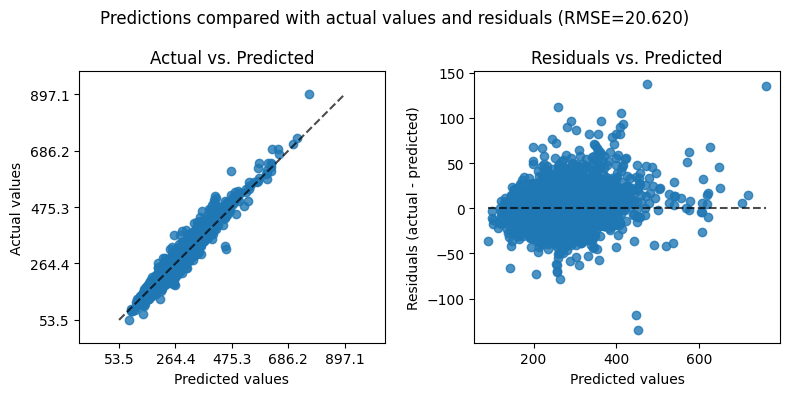

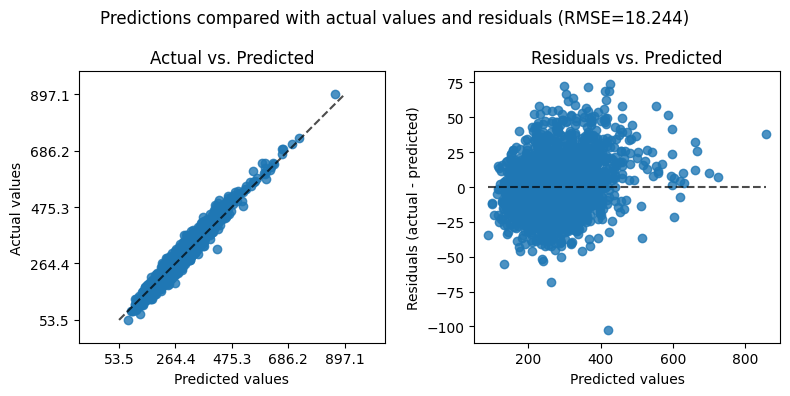

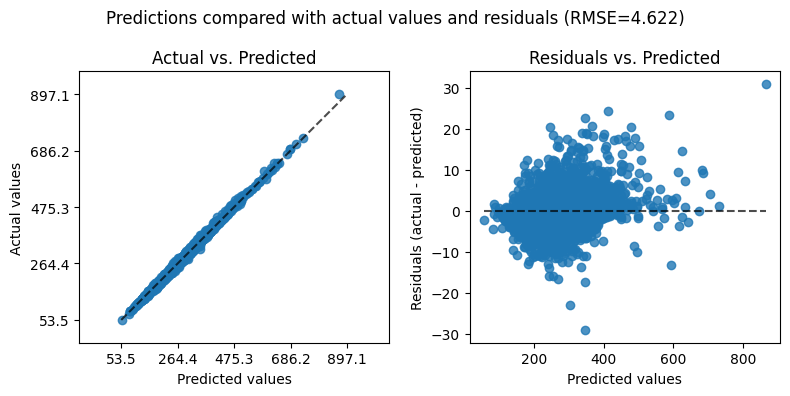

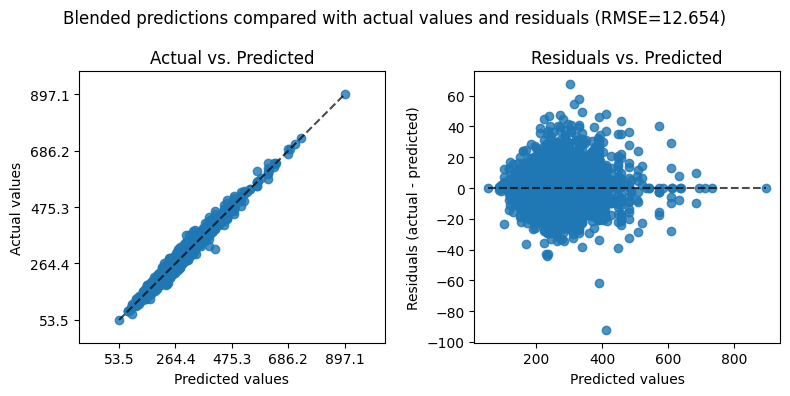

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem import rdMolDescriptors
from rdkit import RDLogger
from rdkit.Chem.rdMolDescriptors import GetMorganFingerprintAsBitVect, GetMACCSKeysFingerprint
from rdkit.Chem import Descriptors, Lipinski
import warnings
import multiprocessing

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')
RDLogger.DisableLog('rdApp.*')

## 1. Read data
# read train data into dataframe train
train_path = "/kaggle/input/melting-point/train.csv"
df_train = pd.read_csv(train_path)
print("Train dataset shape is {}".format(df_train.shape))

# read test data into dataframe test
test_path = "/kaggle/input/melting-point/test.csv"
df_test = pd.read_csv(test_path)
print("Test dataset shape is {}".format(df_test.shape))


## 2. Add chemichal properties
descriptor_list = [d[0] for d in Descriptors.descList]
TARGET = 'Tm'
SMILES_COL = 'SMILES'

def generate_features_from_smiles(smiles_list):
    """Generates all features for a list of SMILES strings using RDKit."""
    features = []
    for smiles in tqdm(smiles_list, desc="Processing SMILES", leave=False):
        mol = Chem.MolFromSmiles(smiles)
        
        feature_dict = {}
        if mol is not None:
            # Standard Descriptors
            for name, func in Descriptors.descList:
                try:
                    feature_dict[name] = func(mol)
                except Exception:
                    feature_dict[name] = np.nan
            
            # Morgan Fingerprint (using GetMorganFingerprintAsBitVect to avoid deprecation)
            fp_morgan = GetMorganFingerprintAsBitVect(mol, radius=2, nBits=1024)
            for i in range(1024):
                feature_dict[f"Morgan_{i}"] = int(fp_morgan.GetBit(i))
            
            # MACCS Keys
            fp_maccs = GetMACCSKeysFingerprint(mol)
            for i in range(167):  # MACCS has 167 bits
                feature_dict[f"MACCS_{i}"] = int(fp_maccs.GetBit(i))
                
            # Additional custom features - FIXED NAMES
            feature_dict['NumRotatableBonds'] = Descriptors.NumRotatableBonds(mol)
            feature_dict['NumHDonors'] = Lipinski.NumHDonors(mol)  # Fixed
            feature_dict['NumHAcceptors'] = Lipinski.NumHAcceptors(mol)  # Fixed
            feature_dict['MolLogP'] = Descriptors.MolLogP(mol)
            feature_dict['TPSA'] = Descriptors.TPSA(mol)
        else:
            # If molecule parsing fails, fill with zeros
            for name, _ in Descriptors.descList:
                feature_dict[name] = 0
            for i in range(1024):
                feature_dict[f"Morgan_{i}"] = 0
            for i in range(167):
                feature_dict[f"MACCS_{i}"] = 0
            feature_dict['NumRotatableBonds'] = 0
            feature_dict['NumHDonors'] = 0
            feature_dict['NumHAcceptors'] = 0
            feature_dict['MolLogP'] = 0
            feature_dict['TPSA'] = 0

        features.append(feature_dict)
    return features

def parallel_feature_generation(smiles_list, num_workers):
    """Splits the SMILES list and generates features in parallel."""
    chunks = np.array_split(smiles_list, num_workers)
    with multiprocessing.Pool(processes=num_workers) as pool:
        results = pool.map(generate_features_from_smiles, chunks)
    
    return [item for sublist in results for item in sublist]

num_cores = min(4, multiprocessing.cpu_count())  # Limit cores to avoid memory issues
print(f"Using {num_cores} CPU cores")
train_features_list = parallel_feature_generation(df_train[SMILES_COL].tolist(), num_cores)
test_features_list = parallel_feature_generation(df_test[SMILES_COL].tolist(), num_cores)
X_train = pd.DataFrame(train_features_list).fillna(0)
X_test = pd.DataFrame(test_features_list).fillna(0)
# X_train = generate_features_from_smiles(df_train[SMILES_COL].tolist())
# X_test = generate_features_from_smiles(df_test[SMILES_COL].tolist())
y_train = df_train[TARGET].values
print('Done adding chemical properties')


## 3. Add feature interactions
# X_train
X_train['HBond_Product'] = X_train['NumHDonors'] * X_train['NumHAcceptors']
X_train['HBond_Sum'] = X_train['NumHDonors'] + X_train['NumHAcceptors']
X_train['LogP_div_TPSA'] = X_train['MolLogP'] / (X_train['TPSA'] + 1)
X_train['LogP_x_TPSA'] = X_train['MolLogP'] * X_train['TPSA']
X_train['Flexibility_Score'] = X_train['NumRotatableBonds'] / (X_train['MolWt'] + 1)
X_train['MolWt_x_AromaticRings'] = X_train['MolWt'] * X_train['NumAromaticRings']
X_train['Complexity_per_MW'] = X_train['BertzCT'] / (X_train['MolWt'] + 1)
X_train['Rigidity_Score'] = X_train['NumAromaticRings'] / (X_train['NumRotatableBonds'] + 1)

# X_test
X_test['HBond_Product'] = X_test['NumHDonors'] * X_test['NumHAcceptors']
X_test['HBond_Sum'] = X_test['NumHDonors'] + X_test['NumHAcceptors']
X_test['LogP_div_TPSA'] = X_test['MolLogP'] / (X_test['TPSA'] + 1)
X_test['LogP_x_TPSA'] = X_test['MolLogP'] * X_test['TPSA']
X_test['Flexibility_Score'] = X_test['NumRotatableBonds'] / (X_test['MolWt'] + 1)
X_test['MolWt_x_AromaticRings'] = X_test['MolWt'] * X_test['NumAromaticRings']
X_test['Complexity_per_MW'] = X_test['BertzCT'] / (X_test['MolWt'] + 1)
X_test['Rigidity_Score'] = X_test['NumAromaticRings'] / (X_test['NumRotatableBonds'] + 1)

print('Done generating feature interactions')

## 3. LightGBM
kwargs = {

    # PyMLR, optuna, and cross_val_score hyperparameters
    'n_trials': 5,               # number of optuna trials
    'classify': False,           # True= LGBMClassifier, False= LGBMRegressor
    'feature_selection': False,  # True= optimize selected features
    'threshold_cat': 12,         # one-hot encode <= threshold_cat
    'scoring': "neg_mean_absolute_error",
    'show_trial_progress': True,    # show best cv score at each trial
    'random_state': 42,          # random seed for reproducibility
    'gpu': False,                # False= use CPU

    # LightGBM hyperparameters (ranges optimized by optuna)
    'num_threads': -1,           # -1 to use all cpus
    'objective': 'regression',   # 'regression', 'binary', or 'multiclass'
    'verbosity': -1,                                    
    'learning_rate': [1e-3, 1],  
    'n_estimators': [100, 3000],  
    'num_leaves': [16, 256],
    'max_depth': [3, 15],
    'min_child_samples': [5, 100],
    'subsample': [0.5, 1.0],
    'colsample_bytree': [0.5, 1.0],
    'reg_alpha': [1e-8, 10.0],
    'reg_lambda': [1e-8, 10.0],
    'min_split_gain': [0.0, 1.0],
    'min_child_weight': [1e-3, 10.0],
    'class_weight': [None, "balanced"],
    'boosting_type': ["gbdt", "dart"],

}

# Fit the model with the training data
from PyMLR import lgbm_auto
train_model_lgbm, train_output_lgbm = lgbm_auto(X_train, y_train, **kwargs)

from PyMLR import preprocess_test

preprocess_result= train_output_lgbm['preprocess_result']
selected_features= train_output_lgbm['selected_features']
X_test_proc = preprocess_test(X_test, preprocess_result)
model = train_model_lgbm
y_pred = model.predict(X_test_proc[selected_features])

# Save your predictions as a CSV
to_save = df_test[['id']].copy()
to_save.loc[:, 'Tm'] = y_pred
to_save.to_csv('/kaggle/working/submission_lgbm.csv', index=False)


# Save train y_pred for later calculation of ensemble predictions
to_save = df_train[['id']].copy()
to_save.loc[:, 'y_train'] = y_train
to_save.loc[:, 'y_train_pred'] = train_output_lgbm['y_pred']
to_save.to_csv('/kaggle/working/lgbm_train_preds.csv', index=False)

## 4. Catboost
kwargs = {

    # PyMLR, optuna, and cross_val_score hyperparameters
    'n_trials': 5,
    'classify': False,        # True= CatBoostClassifier, False= CatBoostRegressor
    'feature_selection': False,         # True= optimize selected features
    'threshold_cat': 12,                # one-hot encode <= threshold_cat
    'scoring': "neg_mean_absolute_error",
    'show_trial_progress': True,        # show best cv score at each trial
    'random_state': 42,                 # random seed for reproducibility
    'gpu': False,                       # False= use CPU

    # CatBoost hyperparameters (ranges optimized by optuna)
    'thread_count': -1,                 # num of available cpus
    'learning_rate': [0.01, 0.3],       # Balances step size in gradient updates.
    'depth': [4, 10],                   # Controls tree depth
    'iterations': [100, 3000],          # Number of boosting iterations
    'l2_leaf_reg': [1, 10],             # Regularization strength       
    'random_strength': [0, 1],          # Adds noise for diversity
    'bagging_temperature': [0.1, 1.0],  # Controls randomness in sampling
    'border_count': [32, 255],          # Number of bins for feature discretization
    'min_data_in_leaf': [1, 100],       # Minimum samples per leaf         
    'max_bin': [64, 255],
    'bootstrap_type': ["Bernoulli"],  
    'subsample': [0.5, 1.0]

}    

from PyMLR import catboost_auto
train_model_cat, train_output_cat = catboost_auto(X_train, y_train, **kwargs)


# Save test y_pred for later calculation of ensemble predictions

from PyMLR import preprocess_test

preprocess_result= train_output_cat['preprocess_result']
selected_features= train_output_cat['selected_features']
X_test_proc = preprocess_test(X_test, preprocess_result)
model = train_model_cat
y_pred = model.predict(X_test_proc[selected_features])

# Save your predictions as a CSV
to_save = df_test[['id']].copy()
to_save.loc[:, 'Tm'] = y_pred
to_save.to_csv('/kaggle/working/submission_cat.csv', index=False)

# Save train y_pred for later calculation of ensemble predictions
to_save = df_train[['id']].copy()
to_save.loc[:, 'y_train'] = y_train
to_save.loc[:, 'y_train_pred'] = train_output_cat['y_pred']
to_save.to_csv('/kaggle/working/cat_train_preds.csv', index=False)

# 4. XGBoost
kwargs = {

    # PyMLR, optuna, and cross_val_score hyperparameters
    'n_trials': 5,                  # number of optuna trials
    'classify': False,              # True= XGBClassifier, False= XGBRegressor
    'feature_selection': False,     # True= optimize selected features
    'threshold_cat': 12,            # one-hot encode <= threshold_cat
    'scoring': "neg_mean_absolute_error",
    'show_trial_progress': True,    # show best cv score at each trial
    'random_state': 42,             # random seed for reproducibility
    'gpu': False,                   # True= use GPU, False= use CPU

    # XGBoost hyperparameters (ranges optimized by optuna)
    'nthread': -1,                  # number of cpu cores
    'learning_rate': [1e-4, 1.0],   # step size shrinkage (also called eta)
    'max_depth': [3, 15],           # maximum depth of a tree
    'min_child_weight': [1, 10],    # minimum sum of instance weight (hessian) needed in a child
    'subsample': [0.5, 1],          # fraction of samples used for training each tree
    'colsample_bytree': [0.5, 1],   # fraction of features used for each tree
    'gamma': [1e-8, 10.0],          # minimum loss reduction to make a split
    'reg_lambda': [1e-8, 10.0],     # L2 regularization term on weights
    'alpha': [1e-8, 10.0],          # L1 regularization term on weights
    'n_estimators': [100, 2000]     # number of boosting rounds (trees)

}    

from PyMLR import xgb_auto
train_model_xgb, train_output_xgb = xgb_auto(X_train, y_train, **kwargs)

# Save test y_pred for later calculation of ensemble predictions

from PyMLR import preprocess_test

preprocess_result= train_output_xgb['preprocess_result']
selected_features= train_output_xgb['selected_features']
X_test_proc = preprocess_test(X_test, preprocess_result)
model = train_model_xgb
y_pred = model.predict(X_test_proc[selected_features])

# Save your predictions as a CSV
to_save = df_test[['id']].copy()
to_save.loc[:, 'Tm'] = y_pred
to_save.to_csv('/kaggle/working/submission_xgb.csv', index=False)

# Save train y_pred for later calculation of ensemble predictions

to_save = df_train[['id']].copy()
to_save.loc[:, 'y_train'] = y_train
to_save.loc[:, 'y_train_pred'] = train_output_xgb['y_pred']
to_save.to_csv('/kaggle/working/xgb_train_preds.csv', index=False)

## 5. Ensemble blend of of LightGBM, CatBoost, and XGBoost
# LightGBM predictions
# test
test_path_lgb = "/kaggle/working/submission_lgbm.csv"
df_test_lgb = pd.read_csv(test_path_lgb)
lgb_test_preds = df_test_lgb['Tm']
# train
train_path_lgb = "/kaggle/working/lgbm_train_preds.csv"
df_train_lgb = pd.read_csv(train_path_lgb)
lgb_train_preds = df_train_lgb['y_train_pred']

# CatBoost predictions
# test
test_path_cat = "/kaggle/working/submission_cat.csv"
df_test_cat = pd.read_csv(test_path_cat)
cat_test_preds = df_test_cat['Tm']
# train
train_path_cat = "/kaggle/working/cat_train_preds.csv"
df_train_cat = pd.read_csv(train_path_cat)
cat_train_preds = df_train_cat['y_train_pred']

# XGBoost predictions
# test
test_path_xgb = "/kaggle/working/submission_xgb.csv"
df_test_xgb = pd.read_csv(test_path_xgb)
xgb_test_preds = df_test_xgb['Tm']
# train
train_path_xgb = "/kaggle/working/xgb_train_preds.csv"
df_train_xgb = pd.read_csv(train_path_xgb)
xgb_train_preds = df_train_xgb['y_train_pred']

# Base model predictions and true values of y for training
preds_train_df = pd.DataFrame({
    'xgb': xgb_train_preds,  # XGBoost predictions using X_train
    'cat': cat_train_preds,  # CatBoost predictions using X_train
    'lgb': lgb_train_preds   # LightGBM predictions using X_train
})
y_train = df_train_lgb['y_train']

# Base model predictions for independent test set
preds_test_df = pd.DataFrame({
    'xgb': xgb_test_preds,  # XGBoost predictions using X_test
    'cat': cat_test_preds,  # CatBoost predictions using X_test
    'lgb': lgb_test_preds   # LightGBM predictions using X_test
})

print('Ensemble Done')

# Calculate ensemble blended prediction using isotonic regression

from PyMLR import isotonic_blend
result = isotonic_blend(preds_test_df, preds_train_df, y_train)

print('Isotonic regression done')

# Submission
to_save = df_test[['id']].copy()
to_save.loc[:, 'Tm'] = result
to_save.to_csv('/kaggle/working/Submission_isotonic_blend.csv', index=False)

print('Done')

## 17. Igual que 13 sin Groups

In [3]:
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors, AllChem, DataStructs
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
import xgboost as xgb
import optuna
import warnings

warnings.filterwarnings("ignore")

# -------------------------
# 1. Cargar datos
# -------------------------
train_df = pd.read_csv("/kaggle/input/melting-point/train.csv")
test_df = pd.read_csv("/kaggle/input/melting-point/test.csv")

y = train_df["Tm"].values
mean_Tm, std_Tm = y.mean(), y.std()
y_norm = (y - mean_Tm) / std_Tm

# -------------------------
# 2. Funciones auxiliares
# -------------------------
def morgan_fp(smiles, nBits=1024, radius=2):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.zeros(nBits)
    gen = AllChem.GetMorganGenerator(radius=radius, fpSize=nBits)
    fp = gen.GetFingerprint(mol)
    arr = np.zeros((nBits,), dtype=int)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

def rdkit_desc(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return [0]*9
    return [
        Descriptors.MolWt(mol),
        Descriptors.MolLogP(mol),
        Descriptors.TPSA(mol),
        rdMolDescriptors.CalcNumRings(mol),
        Descriptors.NumRotatableBonds(mol),
        rdMolDescriptors.CalcNumHBD(mol),
        rdMolDescriptors.CalcNumHBA(mol),
        rdMolDescriptors.CalcNumAromaticRings(mol),
        Descriptors.BertzCT(mol)
    ]

rdkit_names = [
    "MolWt", "MolLogP", "TPSA", "NumRings", "NumRotatableBonds",
    "NumHDonors", "NumHAcceptors", "NumAromaticRings", "BertzCT"
]

# -------------------------
# 3. Features
# -------------------------
fps_train = np.vstack([morgan_fp(s) for s in train_df["SMILES"]])
fps_test = np.vstack([morgan_fp(s) for s in test_df["SMILES"]])

pca = PCA(n_components=128, random_state=42)
fps_train_pca = pca.fit_transform(fps_train)
fps_test_pca = pca.transform(fps_test)

rdkit_train = np.vstack([rdkit_desc(s) for s in train_df["SMILES"]])
rdkit_test = np.vstack([rdkit_desc(s) for s in test_df["SMILES"]])

rdkit_train_df = pd.DataFrame(rdkit_train, columns=rdkit_names)
rdkit_test_df = pd.DataFrame(rdkit_test, columns=rdkit_names)

# ➕ Nuevas variables de interacción
for df in [rdkit_train_df, rdkit_test_df]:
    df["HBond_Product"] = df["NumHDonors"] * df["NumHAcceptors"]
    df["HBond_Sum"] = df["NumHDonors"] + df["NumHAcceptors"]
    df["LogP_div_TPSA"] = df["MolLogP"] / (df["TPSA"] + 1)
    df["LogP_x_TPSA"] = df["MolLogP"] * df["TPSA"]
    df["Flexibility_Score"] = df["NumRotatableBonds"] / (df["MolWt"] + 1)
    df["MolWt_x_AromaticRings"] = df["MolWt"] * df["NumAromaticRings"]
    df["Complexity_per_MW"] = df["BertzCT"] / (df["MolWt"] + 1)
    df["Rigidity_Score"] = df["NumAromaticRings"] / (df["NumRotatableBonds"] + 1)

# ❌ Eliminamos las variables Group
X_train = np.hstack([rdkit_train_df.values, fps_train_pca])
X_test = np.hstack([rdkit_test_df.values, fps_test_pca])

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# -------------------------
# 4. Optuna tuning con GPU
# -------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)

def objective_xgb(trial):
    params = {
        "objective": "reg:squarederror",
        "eval_metric": "mae",
        "tree_method": "hist",
        "predictor": "auto",
        "learning_rate": trial.suggest_loguniform("learning_rate", 1e-3, 0.1),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 20),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "lambda": trial.suggest_loguniform("lambda", 1e-8, 10.0),
        "alpha": trial.suggest_loguniform("alpha", 1e-8, 10.0),
        "n_estimators": 2000,
        "early_stopping_rounds": 50,
        "random_state": 42,
        "verbosity": 0
    }

    maes = []
    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train[tr_idx], X_train[val_idx]
        y_tr, y_val = y_norm[tr_idx], y_norm[val_idx]

        model = xgb.XGBRegressor(**params)
        model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)

        preds = model.predict(X_val)
        maes.append(mean_absolute_error(y_val*std_Tm+mean_Tm, preds*std_Tm+mean_Tm))

    return np.mean(maes)

study_xgb = optuna.create_study(direction="minimize")
study_xgb.optimize(objective_xgb, n_trials=20)
best_xgb_params = study_xgb.best_params
print("\n🎯 Best XGBoost params:", best_xgb_params)

# -------------------------
# 5. Validación con mejores parámetros
# -------------------------
maes = []
for tr_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train[tr_idx], X_train[val_idx]
    y_tr, y_val = y_norm[tr_idx], y_norm[val_idx]

    model = xgb.XGBRegressor(
        **best_xgb_params,
        objective="reg:squarederror",
        eval_metric="mae",
        n_estimators=2000,
        early_stopping_rounds=50,
        tree_method="hist",
        predictor="auto",
        random_state=42,
        verbosity=0
    )
    model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
    preds = model.predict(X_val)
    maes.append(mean_absolute_error(y_val*std_Tm+mean_Tm, preds*std_Tm+mean_Tm))

print(f"\n✅ MAE medio validación (5-Fold): {np.mean(maes):.4f}")

# -------------------------
# 6. Entrenar modelo final
# -------------------------
final_model = xgb.XGBRegressor(
    **best_xgb_params,
    objective="reg:squarederror",
    eval_metric="mae",
    n_estimators=2000,
    early_stopping_rounds=50,
    tree_method="hist",
    predictor="auto",
    random_state=42,
    verbosity=0
)
final_model.fit(X_train, y_norm, eval_set=[(X_train, y_norm)], verbose=False)

# -------------------------
# 7. Submission
# -------------------------
preds_test = final_model.predict(X_test)
preds_test = preds_test*std_Tm + mean_Tm

submission = pd.DataFrame({"id": test_df["id"], "Tm": preds_test})
# submission.to_csv("/kaggle/working/submission_no_groups.csv", index=False)
# print("\n📁 Submission guardada en /kaggle/working/submission_no_groups.csv")


[I 2025-09-24 19:46:02,766] A new study created in memory with name: no-name-1b8d8465-00a2-47c2-bc20-39dd58d12d66
[I 2025-09-24 19:47:28,306] Trial 0 finished with value: 29.999823231515016 and parameters: {'learning_rate': 0.019906652907580116, 'max_depth': 10, 'min_child_weight': 17, 'subsample': 0.728966382206303, 'colsample_bytree': 0.9878320173881618, 'lambda': 1.851021756159816e-05, 'alpha': 0.0037499470967368677}. Best is trial 0 with value: 29.999823231515016.
[I 2025-09-24 19:47:56,326] Trial 1 finished with value: 30.260867892312312 and parameters: {'learning_rate': 0.04311484704518441, 'max_depth': 5, 'min_child_weight': 18, 'subsample': 0.6052079843611017, 'colsample_bytree': 0.9337663058118923, 'lambda': 0.000381028054816575, 'alpha': 0.000830233551847975}. Best is trial 0 with value: 29.999823231515016.
[I 2025-09-24 19:48:07,500] Trial 2 finished with value: 31.13596814280313 and parameters: {'learning_rate': 0.06683329965069101, 'max_depth': 3, 'min_child_weight': 18, '


🎯 Best XGBoost params: {'learning_rate': 0.0074961849049386175, 'max_depth': 6, 'min_child_weight': 1, 'subsample': 0.8111637697146945, 'colsample_bytree': 0.6407338423072584, 'lambda': 4.968132798624766e-05, 'alpha': 0.00012029955212549583}

✅ MAE medio validación (5-Fold): 29.3225


## 18. RDKit + Morgan fingerprints (PCA) + Interaction Features + Isotonic Stacking (XGBoost, LightGBM, CatBoost)

In [ ]:
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors, AllChem, DataStructs
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
from sklearn.isotonic import IsotonicRegression
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor
import optuna
import warnings

warnings.filterwarnings("ignore")

# -------------------------
# 1. Cargar datos
# -------------------------
train_df = pd.read_csv("/kaggle/input/melting-point/train.csv")
test_df = pd.read_csv("/kaggle/input/melting-point/test.csv")

y = train_df["Tm"].values
mean_Tm, std_Tm = y.mean(), y.std()
y_norm = (y - mean_Tm) / std_Tm

# -------------------------
# 2. Funciones auxiliares
# -------------------------
def morgan_fp(smiles, nBits=1024, radius=2):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.zeros(nBits)
    gen = AllChem.GetMorganGenerator(radius=radius, fpSize=nBits)
    fp = gen.GetFingerprint(mol)
    arr = np.zeros((nBits,), dtype=int)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

def rdkit_desc(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return [0]*9
    return [
        Descriptors.MolWt(mol),
        Descriptors.MolLogP(mol),
        Descriptors.TPSA(mol),
        rdMolDescriptors.CalcNumRings(mol),
        Descriptors.NumRotatableBonds(mol),
        rdMolDescriptors.CalcNumHBD(mol),
        rdMolDescriptors.CalcNumHBA(mol),
        rdMolDescriptors.CalcNumAromaticRings(mol),
        Descriptors.BertzCT(mol)
    ]

rdkit_names = [
    "MolWt", "MolLogP", "TPSA", "NumRings", "NumRotatableBonds",
    "NumHDonors", "NumHAcceptors", "NumAromaticRings", "BertzCT"
]

# -------------------------
# 3. Features
# -------------------------
fps_train = np.vstack([morgan_fp(s) for s in train_df["SMILES"]])
fps_test = np.vstack([morgan_fp(s) for s in test_df["SMILES"]])

pca = PCA(n_components=128, random_state=42)
fps_train_pca = pca.fit_transform(fps_train)
fps_test_pca = pca.transform(fps_test)

rdkit_train = np.vstack([rdkit_desc(s) for s in train_df["SMILES"]])
rdkit_test = np.vstack([rdkit_desc(s) for s in test_df["SMILES"]])

rdkit_train_df = pd.DataFrame(rdkit_train, columns=rdkit_names)
rdkit_test_df = pd.DataFrame(rdkit_test, columns=rdkit_names)

# ➕ Nuevas variables de interacción
for df in [rdkit_train_df, rdkit_test_df]:
    df["HBond_Product"] = df["NumHDonors"] * df["NumHAcceptors"]
    df["HBond_Sum"] = df["NumHDonors"] + df["NumHAcceptors"]
    df["HBond_Product_w"] = df["HBond_Product"] / df["MolWt"]
    df["HBond_Sum_w"] = df["HBond_Sum"] / df["MolWt"]
    df["LogP_div_TPSA"] = df["MolLogP"] / (df["TPSA"] + 1)
    df["LogP_x_TPSA"] = df["MolLogP"] * df["TPSA"]
    df["Flexibility_Score"] = df["NumRotatableBonds"] / (df["MolWt"] + 1)
    df["MolWt_x_AromaticRings"] = df["MolWt"] * df["NumAromaticRings"]
    df["Complexity_per_MW"] = df["BertzCT"] / (df["MolWt"] + 1)
    df["Rigidity_Score"] = df["NumAromaticRings"] / (df["NumRotatableBonds"] + 1)

X_train = np.hstack([rdkit_train_df.values, fps_train_pca])
X_test = np.hstack([rdkit_test_df.values, fps_test_pca])

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# -------------------------
# 4. Optuna optimization
# -------------------------
def tune_xgb(trial):
    params = {
        "objective": "reg:squarederror",
        "eval_metric": "mae",
        "learning_rate": trial.suggest_loguniform("lr", 1e-3, 0.1),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample", 0.6, 1.0),
        "min_child_weight": trial.suggest_int("min_child", 1, 20),
        "n_estimators": 2000,
        "verbosity": 0,
        "random_state": 42
    }
    maes = []
    for tr_idx, val_idx in kf.split(X_train):
        model = xgb.XGBRegressor(**params)
        model.fit(X_train[tr_idx], y_norm[tr_idx],
                  eval_set=[(X_train[val_idx], y_norm[val_idx])],
                  early_stopping_rounds=50, verbose=False)
        preds = model.predict(X_train[val_idx])
        maes.append(mean_absolute_error(y[val_idx], preds*std_Tm+mean_Tm))
    return np.mean(maes)

def tune_lgb(trial):
    params = {
        "n_estimators": 2000,
        "learning_rate": trial.suggest_loguniform("lr", 1e-3, 0.1),
        "num_leaves": trial.suggest_int("num_leaves", 16, 256),
        "max_depth": trial.suggest_int("max_depth", -1, 12),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample", 0.6, 1.0),
        "random_state": 42,
        "verbose": -1
    }
    maes = []
    for tr_idx, val_idx in kf.split(X_train):
        model = lgb.LGBMRegressor(**params)
        model.fit(X_train[tr_idx], y_norm[tr_idx],
                  eval_set=[(X_train[val_idx], y_norm[val_idx])],
                  eval_metric="mae",
                  callbacks=[lgb.early_stopping(50), lgb.log_evaluation(-1)])
        preds = model.predict(X_train[val_idx])
        maes.append(mean_absolute_error(y[val_idx], preds*std_Tm+mean_Tm))
    return np.mean(maes)

def tune_cat(trial):
    params = {
        "iterations": 2000,
        "learning_rate": trial.suggest_loguniform("learning_rate", 1e-3, 0.1),  # <- aquí el nombre correcto
        "depth": trial.suggest_int("depth", 3, 12),
        "l2_leaf_reg": trial.suggest_loguniform("l2_leaf_reg", 1e-3, 10.0),
        "random_seed": 42,
        "verbose": 0
    }
    maes = []
    for tr_idx, val_idx in kf.split(X_train):
        model = CatBoostRegressor(**params)
        model.fit(
            X_train[tr_idx], y_norm[tr_idx],
            eval_set=(X_train[val_idx], y_norm[val_idx]),
            use_best_model=True,
            early_stopping_rounds=50,
            verbose=0
        )
        preds = model.predict(X_train[val_idx])
        maes.append(mean_absolute_error(y[val_idx], preds*std_Tm+mean_Tm))
    return np.mean(maes)

print("🔎 Optimizando XGBoost...")
study_xgb = optuna.create_study(direction="minimize")
study_xgb.optimize(tune_xgb, n_trials=10)
best_xgb = study_xgb.best_params

print("🔎 Optimizando LightGBM...")
study_lgb = optuna.create_study(direction="minimize")
study_lgb.optimize(tune_lgb, n_trials=10)
best_lgb = study_lgb.best_params

print("🔎 Optimizando CatBoost...")
study_cat = optuna.create_study(direction="minimize")
study_cat.optimize(tune_cat, n_trials=10)
best_cat = study_cat.best_params

# -------------------------
# 6. Entrenar modelos finales
# -------------------------
xgb_final = xgb.XGBRegressor(**best_xgb)
lgb_final = lgb.LGBMRegressor(**best_lgb)
cat_final = CatBoostRegressor(**best_cat)

xgb_final.fit(X_train, y_norm, verbose=False)
lgb_final.fit(X_train, y_norm, callbacks=[lgb.early_stopping(50)])
cat_final.fit(X_train, y_norm, verbose=0)

# -------------------------
# 7. Stacking con regresión isotónica
# -------------------------
# Predicciones base en train
train_preds = np.vstack([
    xgb_final.predict(X_train),
    lgb_final.predict(X_train),
    cat_final.predict(X_train)
]).T

# Meta-modelo isotónico
iso = IsotonicRegression(out_of_bounds="clip")
iso.fit(train_preds.mean(axis=1), y)  # se entrena sobre la media y target original

# Predicciones en test
test_preds = np.vstack([
    xgb_final.predict(X_test),
    lgb_final.predict(X_test),
    cat_final.predict(X_test)
]).T
final_preds = iso.predict(test_preds.mean(axis=1))

# -------------------------
# 8. Submission
# -------------------------
submission = pd.DataFrame({"id": test_df["id"], "Tm": final_preds})
# submission.to_csv("/kaggle/working/submission_stacking_optuna.csv", index=False)
# print("\n📁 Submission guardada: submission_stacking_optuna.csv")


[I 2025-09-25 21:02:54,365] A new study created in memory with name: no-name-faac94b8-b4e1-470e-985a-f52a845e6d6a


🔎 Optimizando XGBoost...


[I 2025-09-25 21:06:41,570] Trial 0 finished with value: 34.05197009908325 and parameters: {'lr': 0.0011786344051776493, 'max_depth': 8, 'subsample': 0.7180883774025367, 'colsample': 0.6771696495601067, 'min_child': 18}. Best is trial 0 with value: 34.05197009908325.
[I 2025-09-25 21:08:20,780] Trial 1 finished with value: 30.079389853500523 and parameters: {'lr': 0.024448572776153882, 'max_depth': 11, 'subsample': 0.8714887099133573, 'colsample': 0.8909255999465927, 'min_child': 20}. Best is trial 1 with value: 30.079389853500523.
[I 2025-09-25 21:11:43,819] Trial 2 finished with value: 29.960844851397894 and parameters: {'lr': 0.007066299724356598, 'max_depth': 11, 'subsample': 0.6514816921515525, 'colsample': 0.6450525032587487, 'min_child': 13}. Best is trial 2 with value: 29.960844851397894.
[I 2025-09-25 21:13:20,175] Trial 3 finished with value: 30.043603943981775 and parameters: {'lr': 0.011111927859336596, 'max_depth': 5, 'subsample': 0.7766479598088134, 'colsample': 0.9063440

Early stopping, best iteration is:
[1000]	valid_0's l1: 0.355933	valid_0's l2: 0.319473
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[2000]	valid_0's l1: 0.366436	valid_0's l2: 0.28097
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[2000]	valid_0's l1: 0.358951	valid_0's l2: 0.262913
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[2000]	valid_0's l1: 0.358948	valid_0's l2: 0.278774
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[1998]	valid_0's l1: 0.3697	valid_0's l2: 0.258724
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[2000]	valid_0's l1: 0.360447	valid_0's l2: 0.322112


[I 2025-09-25 21:27:51,941] Trial 2 finished with value: 30.88318807185224 and parameters: {'lr': 0.0023006339125947474, 'num_leaves': 213, 'max_depth': 10, 'subsample': 0.8614532142277133, 'colsample': 0.663883698418318}. Best is trial 1 with value: 30.48215345816409.


...

[I 2025-09-25 21:31:41,216] Trial 8 finished with value: 30.47511689205756 and parameters: {'lr': 0.09423443271523889, 'num_leaves': 83, 'max_depth': 5, 'subsample': 0.8855906428259908, 'colsample': 0.851776181495026}. Best is trial 6 with value: 30.294292995400276.


Early stopping, best iteration is:
[335]	valid_0's l1: 0.347429	valid_0's l2: 0.309283
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[646]	valid_0's l1: 0.371906	valid_0's l2: 0.284301
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[1393]	valid_0's l1: 0.357217	valid_0's l2: 0.25186
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[764]	valid_0's l1: 0.358132	valid_0's l2: 0.2887
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[1355]	valid_0's l1: 0.354979	valid_0's l2: 0.242103
Training until validation scores don't improve for 50 rounds


[I 2025-09-25 21:31:49,596] Trial 9 finished with value: 30.534046172969585 and parameters: {'lr': 0.03954579521311002, 'num_leaves': 226, 'max_depth': 3, 'subsample': 0.7500509031232688, 'colsample': 0.6398028421202521}. Best is trial 6 with value: 30.294292995400276.
[I 2025-09-25 21:31:49,598] A new study created in memory with name: no-name-3e2fada1-1e7f-464d-9f73-39beee3ba9df


Early stopping, best iteration is:
[1411]	valid_0's l1: 0.351735	valid_0's l2: 0.307132
🔎 Optimizando CatBoost...


[I 2025-09-25 21:43:06,009] Trial 0 finished with value: 30.57118420899142 and parameters: {'learning_rate': 0.04022829121187072, 'depth': 9, 'l2_leaf_reg': 0.07175087317657303}. Best is trial 0 with value: 30.57118420899142.
[I 2025-09-25 21:46:38,567] Trial 1 finished with value: 32.96194273939834 and parameters: {'learning_rate': 0.003582434519200892, 'depth': 6, 'l2_leaf_reg': 0.003783393902567072}. Best is trial 0 with value: 30.57118420899142.
[I 2025-09-25 21:55:11,890] Trial 2 finished with value: 31.69130867082846 and parameters: {'learning_rate': 0.06748184325426146, 'depth': 9, 'l2_leaf_reg': 0.147934334887341}. Best is trial 0 with value: 30.57118420899142.


## 19. Groups + Interaction Features + Isotonic Stacking (XGBoost, LightGBM, CatBoost)

In [3]:
# stacking_isotonic_groups_only.py
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
from sklearn.isotonic import IsotonicRegression
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler

# -------------------------
# 1. Cargar datos
# -------------------------
train_df = pd.read_csv("/kaggle/input/melting-point/train.csv")
test_df = pd.read_csv("/kaggle/input/melting-point/test.csv")
y = train_df["Tm"].values

# -------------------------
# 2. Seleccionar columnas Group
# -------------------------
group_cols = [c for c in train_df.columns if c.startswith("Group")]
if len(group_cols) == 0:
    raise ValueError("No se encontraron columnas que empiecen con 'Group'.")

X_train_base = train_df[group_cols].fillna(0).astype(float)
X_test_base = test_df[group_cols].fillna(0).astype(float)

# -------------------------
# 3. Crear interaction features sin RDKit
# -------------------------
def add_interaction_features(df):
    df = df.copy()
    # Suma total de grupos
    df["Group_Sum"] = df.sum(axis=1)
    # Número de grupos no nulos
    df["Group_Count_Nonzero"] = (df > 0).sum(axis=1)
    # Media y desviación típica
    df["Group_Mean"] = df.mean(axis=1)
    df["Group_Std"] = df.std(axis=1)
    # Energía total (suma de cuadrados)
    df["Group_Energy"] = (df ** 2).sum(axis=1)
    # Entropía (distribución de valores normalizados)
    row_sums = df.sum(axis=1).replace(0, 1)
    probs = df.div(row_sums, axis=0)
    df["Group_Entropy"] = -(probs * np.log(probs + 1e-9)).sum(axis=1)
    # Ratio entre máximo y suma (dispersión)
    df["Group_MaxRatio"] = df.max(axis=1) / (df.sum(axis=1) + 1e-9)
    # Proporción del grupo dominante
    df["Group_Max"] = df.max(axis=1)
    return df.fillna(0)

X_train = add_interaction_features(X_train_base)
X_test = add_interaction_features(X_test_base)

print(f"✅ Features creadas: {X_train.shape[1]} columnas totales")

# -------------------------
# 4. Entrenamiento con K-Fold y Stacking Isotónico
# -------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)

oof_preds = np.zeros((len(X_train), 3))   # XGB, LGB, CAT
test_preds = np.zeros((len(X_test), 3))
fold_maes = []

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_train), 1):
    print(f"\n--- Fold {fold} ---")
    X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
    y_tr, y_val = y[tr_idx], y[val_idx]

    # XGBoost
    xgb_model = xgb.XGBRegressor(
        objective="reg:squarederror",
        eval_metric="mae",
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        verbosity=0
    )
    xgb_model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], early_stopping_rounds=50, verbose=False)
    oof_preds[val_idx, 0] = xgb_model.predict(X_val)
    test_preds[:, 0] += xgb_model.predict(X_test) / kf.n_splits

    # LightGBM
    lgb_model = lgb.LGBMRegressor(
        n_estimators=1000,
        learning_rate=0.05,
        num_leaves=64,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )
    lgb_model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)],
                  eval_metric="mae",
                  callbacks=[lgb.early_stopping(50), lgb.log_evaluation(-1)])
    oof_preds[val_idx, 1] = lgb_model.predict(X_val)
    test_preds[:, 1] += lgb_model.predict(X_test) / kf.n_splits

    # CatBoost
    cat_model = CatBoostRegressor(
        iterations=1000,
        learning_rate=0.05,
        depth=6,
        random_seed=42,
        verbose=0,
        loss_function="MAE"
    )
    cat_model.fit(X_tr, y_tr, eval_set=(X_val, y_val),
                  early_stopping_rounds=50, verbose=0)
    oof_preds[val_idx, 2] = cat_model.predict(X_val)
    test_preds[:, 2] += cat_model.predict(X_test) / kf.n_splits

    # Métrica fold
    val_pred_mean = oof_preds[val_idx].mean(axis=1)
    mae = mean_absolute_error(y_val, val_pred_mean)
    fold_maes.append(mae)
    print(f"MAE Fold {fold}: {mae:.4f}")

print(f"\n✅ MAE medio CV (media de modelos base): {np.mean(fold_maes):.4f}")

# -------------------------
# Meta-modelo RidgeCV
scaler_meta = StandardScaler()
X_meta = scaler_meta.fit_transform(oof_preds)
ridge = RidgeCV(alphas=[0.1, 1.0, 10.0], cv=5)
ridge.fit(X_meta, y)

# Predicción OOF y métrica
oof_ridge = ridge.predict(X_meta)
mae_ridge = mean_absolute_error(y, oof_ridge)
print(f"MAE OOF con Ridge Stacking: {mae_ridge:.4f}")

# Predicción final sobre test
test_meta = scaler_meta.transform(test_preds)
final_preds = ridge.predict(test_meta)

✅ Features creadas: 432 columnas totales

--- Fold 1 ---
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[103]	valid_0's l1: 42.1652	valid_0's l2: 3651.29
MAE Fold 1: 35.9081

--- Fold 2 ---
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[117]	valid_0's l1: 39.9823	valid_0's l2: 3166.41
MAE Fold 2: 34.4193

--- Fold 3 ---
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[83]	valid_0's l1: 39.3112	valid_0's l2: 3192.21
MAE Fold 3: 33.8159

--- Fold 4 ---
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[188]	valid_0's l1: 39.7871	valid_0's l2: 3161.48
MAE Fold 4: 34.8264

--- Fold 5 ---
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[149]	valid_0's l1: 37.3352	valid_0's l2: 3112.15
MAE Fold 5: 32.4059

✅ MAE medio CV (media de modelos base): 34.2751
M

## 20. RDKit + Morgan fingerprints (PCA) + Group + Interaction Features + XGBoost Stacking (XGBoost, LightGBM, CatBoost)

In [ ]:
# stack_gpu_xgb_meta.py
# Requires: rdkit, xgboost (GPU), lightgbm (GPU), catboost (GPU), optuna, scikit-learn, pandas, numpy

import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
from tqdm import tqdm
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors, AllChem, DataStructs

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor

import optuna


# -------------------------
# Config
# -------------------------
TRAIN_CSV = "/kaggle/input/melting-point/train.csv"
TEST_CSV = "/kaggle/input/melting-point/test.csv"
OUT_SUB = "/kaggle/working/submission_stack_xgb_meta_gpu.csv"
RANDOM_STATE = 42
N_FOLDS = 5
N_MORGAN = 2048          # fingerprint bits (increase for more signal)
PCA_DIM = 256            # dimensionality for fingerprint PCA
OPTUNA_TRIALS = 30       # trials per base model (increase if you have time)
EARLY_STOPPING = 100
MAX_ESTIMATORS = 3000    # max trees for base models (early stopping will cut)
VERBOSE = 0

np.random.seed(RANDOM_STATE)

# -------------------------
# 1) Load data
# -------------------------
train_df = pd.read_csv(TRAIN_CSV)
test_df  = pd.read_csv(TEST_CSV)

y = train_df["Tm"].values
mean_Tm, std_Tm = y.mean(), y.std()
y_norm = (y - mean_Tm) / std_Tm   # training scaled target (used in some fits)

print("Train shape:", train_df.shape, "Test shape:", test_df.shape)

# -------------------------
# 2) Feature generation
#    RDKit descriptors + Morgan fingerprint (bit vect) + Group columns + interaction features
# -------------------------
group_cols = [c for c in train_df.columns if c.startswith("Group")]
print(f"Detected {len(group_cols)} group columns")

# RDKit descriptor names we will compute
rdkit_names = [
    "MolWt", "MolLogP", "TPSA", "NumRings", "NumRotatableBonds",
    "NumHDonors", "NumHAcceptors", "NumAromaticRings", "BertzCT"
]

def safe_mol(smiles):
    try:
        return Chem.MolFromSmiles(smiles)
    except:
        return None

def compute_rdkit_descs(smiles_list):
    rows = []
    for s in tqdm(smiles_list, desc="RDKit desc"):
        mol = safe_mol(s)
        if mol is None:
            rows.append([0.0]*len(rdkit_names))
            continue
        try:
            molwt = float(Descriptors.MolWt(mol))
        except:
            molwt = 0.0
        try:
            logp = float(Descriptors.MolLogP(mol))
        except:
            logp = 0.0
        try:
            tpsa = float(Descriptors.TPSA(mol))
        except:
            tpsa = 0.0
        try:
            num_rings = int(rdMolDescriptors.CalcNumRings(mol))
        except:
            num_rings = 0
        try:
            rot = int(Descriptors.NumRotatableBonds(mol))
        except:
            rot = 0
        try:
            hbd = int(rdMolDescriptors.CalcNumHBD(mol))
        except:
            hbd = 0
        try:
            hba = int(rdMolDescriptors.CalcNumHBA(mol))
        except:
            hba = 0
        try:
            arom = int(rdMolDescriptors.CalcNumAromaticRings(mol))
        except:
            arom = 0
        try:
            bertz = float(Descriptors.BertzCT(mol))
        except:
            bertz = 0.0
        rows.append([molwt, logp, tpsa, num_rings, rot, hbd, hba, arom, bertz])
    return np.array(rows, dtype=float)

def morgan_bitvector(smiles, nBits=N_MORGAN, radius=2):
    """
    Devuelve el vector de Morgan fingerprints (bit vector) sin warnings.
    Usa el nuevo generador de RDKit.
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.zeros((nBits,), dtype=np.uint8)
    try:
        gen = AllChem.GetMorganGenerator(radius=radius, fpSize=nBits)
        fp = gen.GetFingerprint(mol)
        arr = np.zeros((nBits,), dtype=np.uint8)
        DataStructs.ConvertToNumpyArray(fp, arr)
        return arr
    except Exception:
        return np.zeros((nBits,), dtype=np.uint8)



# Compute RDKit descriptors
rdkit_train = compute_rdkit_descs(train_df["SMILES"].astype(str).values)
rdkit_test  = compute_rdkit_descs(test_df["SMILES"].astype(str).values)

# Create interaction features from those descriptors
def add_interactions_from_rdkit(df_rd):
    # df_rd: array Nx9, columns in rdkit_names order
    import pandas as pd
    df = pd.DataFrame(df_rd.copy(), columns=rdkit_names)
    df["HBond_Product"] = df["NumHDonors"] * df["NumHAcceptors"]
    df["HBond_Sum"] = df["NumHDonors"] + df["NumHAcceptors"]
    df["LogP_div_TPSA"] = df["MolLogP"] / (df["TPSA"] + 1.0)
    df["LogP_x_TPSA"] = df["MolLogP"] * df["TPSA"]
    df["Flexibility_Score"] = df["NumRotatableBonds"] / (df["MolWt"] + 1.0)
    df["MolWt_x_AromaticRings"] = df["MolWt"] * df["NumAromaticRings"]
    df["Complexity_per_MW"] = df["BertzCT"] / (df["MolWt"] + 1.0)
    df["Rigidity_Score"] = df["NumAromaticRings"] / (df["NumRotatableBonds"] + 1.0)
    return df.values, list(df.columns)

rdkit_train_with_int, rdkit_cols = add_interactions_from_rdkit(rdkit_train)
rdkit_test_with_int, _ = add_interactions_from_rdkit(rdkit_test)

print("RDKit features shape:", rdkit_train_with_int.shape)

# Morgan fingerprints (bits) -> PCA
print("Computing Morgan fingerprints (this can be slow)...")
fps_train = np.vstack([morgan_bitvector(s) for s in tqdm(train_df["SMILES"].astype(str).values, desc="Morgan train")])
fps_test  = np.vstack([morgan_bitvector(s) for s in tqdm(test_df["SMILES"].astype(str).values, desc="Morgan test")])

print("Fingerprint shapes:", fps_train.shape, fps_test.shape)
print(f"Applying PCA to fingerprints -> {PCA_DIM} components")
pca = PCA(n_components=PCA_DIM, random_state=RANDOM_STATE)
fps_train_pca = pca.fit_transform(fps_train.astype(float))
fps_test_pca  = pca.transform(fps_test.astype(float))

# Group features
if len(group_cols) > 0:
    groups_train = train_df[group_cols].fillna(0).astype(float).values
    groups_test  = test_df[group_cols].fillna(0).astype(float).values
else:
    groups_train = np.zeros((len(train_df), 0))
    groups_test  = np.zeros((len(test_df), 0))

# Concatenate final feature matrices
X_train = np.hstack([rdkit_train_with_int, groups_train, fps_train_pca])
X_test  = np.hstack([rdkit_test_with_int,  groups_test,  fps_test_pca])

print("Final feature shapes (train/test):", X_train.shape, X_test.shape)

# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train.astype(float))
X_test  = scaler.transform(X_test.astype(float))

# -------------------------
# 3) Optuna tuning functions (use GPU-accelerated learners)
# -------------------------
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

def objective_xgb(trial):
    param = {
        "objective": "reg:squarederror",
        "eval_metric": "mae",
        "tree_method": "gpu_hist",
        "predictor": "gpu_predictor",
        "learning_rate": trial.suggest_loguniform("xgb_lr", 1e-3, 0.2),
        "max_depth": trial.suggest_int("xgb_max_depth", 3, 10),
        "subsample": trial.suggest_float("xgb_subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("xgb_colsample", 0.5, 1.0),
        "gamma": trial.suggest_float("xgb_gamma", 0.0, 5.0),
        "reg_lambda": trial.suggest_loguniform("xgb_reg_lambda", 1e-8, 10.0),
        "reg_alpha": trial.suggest_loguniform("xgb_reg_alpha", 1e-8, 10.0),
        "n_estimators": MAX_ESTIMATORS,
        "random_state": RANDOM_STATE,
        "verbosity": 0
    }
    maes = []
    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train[tr_idx], X_train[val_idx]
        y_tr, y_val = y_norm[tr_idx], y_norm[val_idx]
        model = xgb.XGBRegressor(**param)
        model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], early_stopping_rounds=EARLY_STOPPING, verbose=False)
        preds = model.predict(X_val)
        maes.append(mean_absolute_error(y_val*std_Tm + mean_Tm, preds*std_Tm + mean_Tm))
    return np.mean(maes)

def objective_lgb(trial):
    param = {
        "n_estimators": MAX_ESTIMATORS,
        "learning_rate": trial.suggest_loguniform("lgb_lr", 1e-3, 0.2),
        "num_leaves": trial.suggest_int("lgb_num_leaves", 16, 512),
        "max_depth": trial.suggest_int("lgb_max_depth", -1, 16),
        "subsample": trial.suggest_float("lgb_subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("lgb_colsample", 0.5, 1.0),
        "reg_alpha": trial.suggest_loguniform("lgb_reg_alpha", 1e-8, 10.0),
        "reg_lambda": trial.suggest_loguniform("lgb_reg_lambda", 1e-8, 10.0),
        "random_state": RANDOM_STATE,
        "device": "gpu",          # require LightGBM built with GPU
        "verbosity": -1
    }
    maes = []
    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train[tr_idx], X_train[val_idx]
        y_tr, y_val = y_norm[tr_idx], y_norm[val_idx]
        model = lgb.LGBMRegressor(**param)
        model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], eval_metric="mae",
                  callbacks=[lgb.early_stopping(EARLY_STOPPING), lgb.log_evaluation(-1)])
        preds = model.predict(X_val)
        maes.append(mean_absolute_error(y_val*std_Tm + mean_Tm, preds*std_Tm + mean_Tm))
    return np.mean(maes)

def objective_cat(trial):
    param = {
        "iterations": MAX_ESTIMATORS,
        "learning_rate": trial.suggest_loguniform("cat_lr", 1e-3, 0.2),
        "depth": trial.suggest_int("cat_depth", 4, 10),
        "l2_leaf_reg": trial.suggest_loguniform("cat_l2", 1e-8, 10.0),
        "random_seed": RANDOM_STATE,
        # GPU settings for CatBoost
        "task_type": "GPU",
        "devices": "0",
        "verbose": False
    }
    maes = []
    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train[tr_idx], X_train[val_idx]
        y_tr, y_val = y_norm[tr_idx], y_norm[val_idx]
        model = CatBoostRegressor(**param)
        model.fit(X_tr, y_tr, eval_set=(X_val, y_val), early_stopping_rounds=EARLY_STOPPING, verbose=False, use_best_model=True)
        preds = model.predict(X_val)
        maes.append(mean_absolute_error(y_val*std_Tm + mean_Tm, preds*std_Tm + mean_Tm))
    return np.mean(maes)

# -------------------------
# 4) Run Optuna studies (one per base model)
# -------------------------
print("Starting Optuna for XGBoost (GPU)...")
study_xgb = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_xgb.optimize(objective_xgb, n_trials=OPTUNA_TRIALS, show_progress_bar=True)
best_xgb = study_xgb.best_params
print("Best XGB params:", best_xgb)

print("Starting Optuna for LightGBM (GPU)...")
study_lgb = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_lgb.optimize(objective_lgb, n_trials=OPTUNA_TRIALS, show_progress_bar=True)
best_lgb = study_lgb.best_params
print("Best LGB params:", best_lgb)

print("Starting Optuna for CatBoost (GPU)...")
study_cat = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_cat.optimize(objective_cat, n_trials=OPTUNA_TRIALS, show_progress_bar=True)
best_cat = study_cat.best_params
print("Best CAT params:", best_cat)

# Fix params for final usage: add GPU flags or full keys expected by constructors
best_xgb.update({
    "objective": "reg:squarederror",
    "eval_metric": "mae",
    "tree_method": "gpu_hist",
    "predictor": "gpu_predictor",
    "n_estimators": MAX_ESTIMATORS,
    "random_state": RANDOM_STATE,
    "verbosity": 0
})

best_lgb.update({
    "n_estimators": MAX_ESTIMATORS,
    "random_state": RANDOM_STATE,
    "device": "gpu",
    "verbosity": -1
})

best_cat.update({
    "iterations": MAX_ESTIMATORS,
    "task_type": "GPU",
    "devices": "0",
    "random_seed": RANDOM_STATE,
    "verbose": False
})

# -------------------------
# 5) Generate OOF preds for stacking and test preds averaged across folds
# -------------------------
oof = np.zeros((len(X_train), 3))
test_preds = np.zeros((len(X_test), 3))

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_train), 1):
    print(f"\n=== Fold {fold} ===")
    X_tr, X_val = X_train[tr_idx], X_train[val_idx]
    y_tr, y_val = y_norm[tr_idx], y_norm[val_idx]

    # XGBoost (GPU)
    model_xgb = xgb.XGBRegressor(**best_xgb)
    model_xgb.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], early_stopping_rounds=EARLY_STOPPING, verbose=False)
    oof[val_idx, 0] = model_xgb.predict(X_val)
    test_preds[:, 0] += model_xgb.predict(X_test) / N_FOLDS

    # LightGBM (GPU)
    model_lgb = lgb.LGBMRegressor(**best_lgb)
    model_lgb.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], eval_metric="mae",
                  callbacks=[lgb.early_stopping(EARLY_STOPPING), lgb.log_evaluation(-1)])
    oof[val_idx, 1] = model_lgb.predict(X_val)
    test_preds[:, 1] += model_lgb.predict(X_test) / N_FOLDS

    # CatBoost (GPU)
    # CatBoost expects raw (not scaled) target; we trained on normalized earlier for tuning,
    # but here keep using normalized to be consistent—CatBoost can train on normalized target too.
    model_cat = CatBoostRegressor(**best_cat)
    model_cat.fit(X_tr, y_tr, eval_set=(X_val, y_val), early_stopping_rounds=EARLY_STOPPING, verbose=False, use_best_model=True)
    oof[val_idx, 2] = model_cat.predict(X_val)
    test_preds[:, 2] += model_cat.predict(X_test) / N_FOLDS

    # Diagnostic per-fold MAE (descaled)
    val_mean = (oof[val_idx].mean(axis=1) * std_Tm) + mean_Tm
    fold_mae = mean_absolute_error(y[val_idx], val_mean)
    print(f"Fold {fold} MAE (mean of bases, descaled): {fold_mae:.4f}")

# -------------------------
# 6) Train XGBoost meta-model on OOF predictions (GPU)
#    Use OOF preds (3 cols) as features; target is y (original scale)
# -------------------------
meta_X = oof  # shape (n_samples, 3) (preds are on normalized target scale)
# meta target: we want meta to predict original target, so provide normalized or not?
# We'll train meta on normalized preds -> normalized target to keep scales consistent
meta_y = y_norm

print("\nTraining meta XGBoost (GPU) on OOF preds...")
meta_param = {
    "objective": "reg:squarederror",
    "eval_metric": "mae",
    "tree_method": "gpu_hist",
    "predictor": "gpu_predictor",
    "learning_rate": 0.05,
    "max_depth": 6,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "n_estimators": 2000,
    "random_state": RANDOM_STATE,
    "verbosity": 0
}
meta_model = xgb.XGBRegressor(**meta_param)
meta_model.fit(meta_X, meta_y, verbose=False)

# Evaluate stacking OOF (descaled)
oof_stack_norm = meta_model.predict(meta_X)
oof_stack = oof_stack_norm * std_Tm + mean_Tm
mae_stack = mean_absolute_error(y, oof_stack)
print(f"\n✅ OOF stacking MAE (descaled): {mae_stack:.4f}")

# -------------------------
# 7) Final predictions: use averaged test_preds (normalized scale) through meta-model
# -------------------------
test_meta_X = test_preds  # shape (n_test, 3)
test_meta_norm = meta_model.predict(test_meta_X)
final_preds = test_meta_norm * std_Tm + mean_Tm

# -------------------------
# 8) Save submission
# -------------------------
submission = pd.DataFrame({"id": test_df["id"].values, "Tm": final_preds})
submission.to_csv(OUT_SUB, index=False)
print("\nSubmission saved to:", OUT_SUB)
print("Done.")


Train shape: (2662, 427) Test shape: (666, 426)
Detected 424 group columns


RDKit desc: 100%|██████████| 666/666 [00:00<00:00, 1604.32it/s]


RDKit features shape: (2662, 17)
Computing Morgan fingerprints (this can be slow)...


Morgan test: 100%|██████████| 666/666 [00:00<00:00, 7431.17it/s]


Fingerprint shapes: (2662, 2048) (666, 2048)
Applying PCA to fingerprints -> 256 components


[I 2025-10-09 19:00:34,132] A new study created in memory with name: no-name-2692461c-5a37-46a8-a510-843cd1b8db77


Final feature shapes (train/test): (2662, 697) (666, 697)
Starting Optuna for XGBoost (GPU)...


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2025-10-09 19:01:46,183] Trial 0 finished with value: 31.732348949558776 and parameters: {'xgb_lr': 0.00727491708802781, 'xgb_max_depth': 10, 'xgb_subsample': 0.892797576724562, 'xgb_colsample': 0.7993292420985183, 'xgb_gamma': 0.7800932022121826, 'xgb_reg_lambda': 2.5348407664333426e-07, 'xgb_reg_alpha': 3.3323645788192616e-08}. Best is trial 0 with value: 31.732348949558776.
[I 2025-10-09 19:01:51,174] Trial 1 finished with value: 34.75417272013057 and parameters: {'xgb_lr': 0.09842315738502598, 'xgb_max_depth': 7, 'xgb_subsample': 0.8832290311184181, 'xgb_colsample': 0.5102922471479012, 'xgb_gamma': 4.8495492608099715, 'xgb_reg_lambda': 0.31044435499483225, 'xgb_reg_alpha': 8.148018307012941e-07}. Best is trial 0 with value: 31.732348949558776.
[I 2025-10-09 19:02:37,789] Trial 2 finished with value: 32.186662322155556 and parameters: {'xgb_lr': 0.002620503255096255, 'xgb_max_depth': 4, 'xgb_subsample': 0.7216968971838151, 'xgb_colsample': 0.762378215816119, 'xgb_gamma': 2.159725